<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/M4_Report_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 103 Group 11 Assignment 2 - Milestone 4: Baseline Modeling, Evaluation & Data Generation Strategy

## Bike Share Station Demand for Growth Planning

### Members
- Karen Junsay
- Aditi Singh
- Matthew Jones
- John Aaron

## Part 1: Experimental Design & Data Preparation

### 1.1 Modeling Objective

**Problem Formulation:** Can we predict the hourly departures and arrivals at bike stations and classify whether the demand for a station is Low, Medium, or High, so that Bike Share Toronto can plan where to add new docks or stations?

**Target Variables:**

1. **Regression:** Departures per station per hour, Arrivals per station per hour during the peak months (May to October).
- For each month, a station is considered as open/operating if there is at least 1 trip starting at that station.
- For open/operating stations, hours with zero trips (ex. typical of night time hours) are included in the model.
- In Milestone 3, we set the following flags in the cleaned data to mark valid or invalid trips:
    - `flag_short`: Trip duration is under 60 seconds
    - `flag_long`: Trip duration is over 6 hours
    - `flag_no_end`: The trip has no `End_Station_Id`
    - `is_valid`: True when none of the flags is set, False if at least one is set
- (a) Departures - Valid trips (rows) have no `flag_short` or `flag_long` set. A missing end station doesn't matter.
- (b) Arrivals - Valid trips (rows) have none of the flags (`flag_short`, `flag_long`, `flag_no_end`) set.
    - Note: We said in Milestone 3 that we would no longer include Arrivals as a target variable due to the missing `End_Station_Id`s. However, after discussion, we have decided that the small percentage of missing `End_Station_Id`s should not affect the model too much, and this target variable is relevant in determining how busy a station is.
- For new stations with no historical data, we will use the average of the 3 nearest stations (using latitude and longitude data) instead of the average of all stations at that hour and day of the week across the GTA. If the new station has no available coordinates, the old value will be used as a default. The assumption we make is that the demand should be similar in stations that are close together. This doesn't take into account the actual topology or neighborhood characteristics which are not included in our datasets. (For example, a new station may be near a subway station which might affect the ridership demand differently from its nearest neighbors.) This is a limitation of our models.

2. **Classification:** Predict the demand of stations during May-October 2025 as Low, Medium, or High, based on the training data from the same months in 2023 and 2024.
- One row is one station in one month. A station-month exists if the station had at least 1 valid departure in that month.
- Demand rate for a station is calculated by the average valid departures per operating day for this version.
    - An operating day is all the days in an operating month (if there is at least 1 valid departure in that month, all days in that month will be considered operating days). This is the same rule as we used for the Regression task, and we keep it here for consistency.
    - Days with no trips in an operating month will have a zero demand.
    - Valid departures use the same `is_valid` flag as in Milestone 3. Arrivals are not included in this rate.
    - Note: There are changes from Milestone 3, namely changing the definition to use operating days instead of the active days, because using active days only hides low-demand stations that may have few active days.
- The thresholds for the classification are the following:
    - Low: Less than 9.03
    - Medium: In between 9.03 - 35.81
    - High: Greater than 35.81
- Stations that first appear in 2025 have no 2023 to 2024 rate and are not in the classification data. They are used only in the business check that compares 2024 High stations with the new 2025 stations.
    

**Features:**

Each ML task has a different set of features.

1. **Regression**
- One row per station per hour
- (a) Features from date/timestamp:

     - `hour_of_day` - categorical values: hr_0-hr_23, rush hour will have different behaviour
     - `day_of_week` - categorical values: Monday(0)-Sunday(6), riding patterns are different on weekdays and weekends
     - `weekend_or_holiday` - flag (1 if weekend or holiday, 0 otherwise)
     - `year` - numerical values: 2023, 2024, 2025
     - `month` - categorical values: May-Oct

- (b) Features from weather

    - `prec_mm_hr` - numerical value, precipitation/rain in that hour
    - `mean_temp_c_hr` - numerical value, temperature in that hour
    - `prec_mm_prev_hr` - numerical value, precipitation/rain in the previous hour (since people check weather before deciding to ride)

- (c) Features from station

    - `station_id` - categorical
    - `new_station` - flag (1 if first month that the station is seen, 0 otherwise). We are doing regression on May to October months only, but we have data from January 2023. We will check for the first occurrence of a station since the very beginning of our data (January 2023) in order to set this flag. (Note that this information is in Milestone 3, since we cleaned the data using the entire dataset)

- (d) New engineered features as of 11/24 after additional exploration and tuning

    - `station_hour_dow_avg` - numerical value, the average departures or arrivals of the station at that hour of day and day of week in the training months. The original models were unable to find the correct shape of individual stations using the original dataset, since the quiet stations at each hour pulled down the predictions for the busy stations. We also added the day of week since the ridership patterns are different for each day of the week, especially comparing weekdays and weekends.
    - `is_raining` - flag (1 if raining at that hour, 0 if not raining)


2. **Classification**

- One row per station per month (May to October)
- (a) Features from month's activity:
     - `monthly_volume` - numerical value, valid departures from the station in that month.
      - `was_flagged_new` - flag (1 if that month is the first month the station appears in the data, 0 otherwise). `is_new_start_station` flag from Milestone 3 on monthly level.

- (b) Features from station history (Milestone 3 station months)
    - `first_year` - numerical value, the year the station first appears in the data.
    - `first_month` - numerical value, the month the station first appears in the data.

### 1.2 Evaluation Criteria aligned with the Problem

Our training-validation-test split has been changed since Milestone 3:
- Training: May-October 2023 + May 2024
- Validation: June-October 2024
- Test: May-October 2025

We will score each model using the Validation set to help choose the best settings (hyperparameter tuning) and models. Once a model and/or its hyperparameter settings have been chosen, we will rerun the training on the Training+Validation set and evaluate this final model on the Test set once at the end.

1. **Regression** (departures per hour, arrivals per hour)
- Performance metrics: MAE, RMSE for departures and arrivals separately, since they are separate models.
- Baseline to compare against: average departures/arrivals for the same station, hour of day, and day of week in the training months. For stations with no historical data, the baseline will also use the average values of the 3 nearest stations for that hour and day of the week and fall back to the city-wide average if the station also has no available coordinates.
- Success criteria: MAE on Test set should be lower than the baseline for both departures and arrivals.

2. **Classification**
- Performance metrics: Accuracy, precision, recall, f1 score and ROC curves.
- Baseline to compare against: Thresholds for low, medium and high use stations. Compare by looking at data and finding good thresholds to use.
- Success criteria: If our classifiers can reduce false positive so the planner adds bikes and stations only where they're needed.

3. **Business check (optional)**
- Compare the stations classified as High in 2024 with the stations that first appear in 2025, to see whether Bike Share Toronto's expansion followed the high-demand stations. This is to check whether our project's outputs would be useful for growth planning, according to the problem formulation we were trying to solve.

### 1.3 Preprocessing

This section builds the feature tables for the regression and classification models:
1. **Station-hour table** - For regression tasks (departures and arrivals): 1 row per station per hour. Features are departures, arrivals, time/calendar-related, weather, and new-station flag to mark if a station is new for that month.
2. **Station-month table** -- For classification task: 1 row per station per month. Features include monthly_volume, was_flagged_new, first_year and first_month.

#### 1.3.1 Trip data

1. **Limit to peak season only (May to October months)** - Bike share demand is seasonal as we observed in Milestone 3 exploration. Since our business problem is to use our model to help determine areas of growth where new docks or bikes may be placed, we will limit our trip data to the most active summer months and include the months where activity begins to increase more each year as well we the months after summer when bike ridership slows down.

2. **Trip Validity** - Use the flags defined in Milestone 3: `flag_short`, `flag_long`, `flag_no_end`, and `is_valid`. (Refer to 1.1 Target Variables for the same definitions in this notebook) Since we are predicting departures and arrivals separately, counted trips for each regression task use the flags differently:
- **Departures** Using the start station: a trip counts as valid if it has neither `flag_short` nor `flag_long`. Missing end station doesn't matter for departures.
- **Arrivals** Using the End station: a trip counts as valid only if `is_valid` is true (this flag considers the `flag_no_end` as well as the other 2 flags and is true only if none of them are set).

In [1]:
# Read file and set up dataframe

import os, glob, re, time
import numpy as np
import pandas as pd

# 1. Setup and paths (same pattern as the other notebooks)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"
    REFERENCE = f"{DATA}/reference"
    WEATHER_XLSX = f"{DATA}/bike_stations_hourly_weather_analyzed.xlsx"  # output of 03_testing_code.ipynb
else:
    DATA = "../data"
    REFERENCE = "../reference"
    WEATHER_XLSX = f"{DATA}/external/bike_stations_hourly_weather_analyzed.xlsx"

CLEAN = f"{DATA}/clean"
AGG = f"{DATA}/aggregate"
os.makedirs(AGG, exist_ok=True)

YEARS = [2023, 2024, 2025]
MONTHS = list(range(5, 11)) # May to October

def clean_file(year, month):
    return f"{CLEAN}/clean_ridership_{year}_{month:02d}.csv"

print("Clean files found:", sum(os.path.exists(clean_file(y, m)) for y in YEARS for m in MONTHS), "of", len(YEARS) * len(MONTHS))


USECOLS = ["Trip_Id", "Start_Time", "End_Time", "Start_Station_Id", "End_Station_Id",
           "flag_short", "flag_long", "flag_no_end", "is_valid"]

def read_clean(path):
    df = pd.read_csv(path, usecols=USECOLS, parse_dates=["Start_Time", "End_Time"],
                     dtype={"Start_Station_Id": "Int64", "End_Station_Id": "Int64"})
    df["start_hour"] = df["Start_Time"].dt.floor("h")
    df["end_hour"] = df["End_Time"].dt.floor("h")
    return df

## Aggregate departures and arrivals per station per hour in one month
def aggregate_month(df):
    dep_rows = df[~(df["flag_short"] | df["flag_long"])]
    dep = (dep_rows.groupby(["Start_Station_Id", "start_hour"]).size().rename("departures")
           .reset_index().rename(columns={"Start_Station_Id": "station_id", "start_hour": "hour_ts"}))
    arr_rows = df[df["is_valid"]]
    arr = (arr_rows.groupby(["End_Station_Id", "end_hour"]).size().rename("arrivals")
           .reset_index().rename(columns={"End_Station_Id": "station_id", "end_hour": "hour_ts"}))
    out = dep.merge(arr, on=["station_id", "hour_ts"], how="outer")
    out["departures"] = out["departures"].fillna(0).astype("int64")
    out["arrivals"] = out["arrivals"].fillna(0).astype("int64")
    return out

# Check on one month: the counts must add up to the trips we meant to count
jul23 = read_clean(clean_file(2023, 7))
sh = aggregate_month(jul23)
print(f"JULY 2023 Check - Trips in: {len(jul23):,}   station-hours out: {len(sh):,}")
print("Departures counted:", f"{sh['departures'].sum():,}", " trips not short/long:", f"{(~(jul23['flag_short'] | jul23['flag_long'])).sum():,}")
print("Arrivals counted:  ", f"{sh['arrivals'].sum():,}", " trips valid:         ", f"{jul23['is_valid'].sum():,}")

Mounted at /content/drive
Clean files found: 18 of 18
JULY 2023 Check - Trips in: 735,924   station-hours out: 288,233
Departures counted: 733,606  trips not short/long: 733,606
Arrivals counted:   733,428  trips valid:          733,428


#### 1.3.2 Station-hour table

1. **Include Zero-trip hours** - The group agreed to include hours with zero trips in operating months (ex. nighttime hours) because excluding them may give the model incorrect information about the true demand of a station. We build the the station-hour table for operating stations for every hour of the month. If there are missing hours, we assume that they are missing because there are no trips recorded in the dataset and the counts will be set to 0. (Same approach as Milestone 3. For this Milestone, we apply the same approach to arrivals.)

2. **Add Time-related columns from timestamps** - These are the following features needed for the regression tasks: `hour_of_day`, `day_of_week`, `year`, `month`. The `weekend_or_holiday` flag and other features not created directly from the timestamps will be added later.

In [2]:
# Zero-trip hours
def add_zerotrip_hours(sh, year, month):
    hours = pd.date_range(f"{year}-{month:02d}-01", periods=pd.Period(f"{year}-{month:02d}").days_in_month * 24, freq="h")
    # trips can end in the next month; keep only hours inside this month so months do not overlap
    sh = sh[(sh["hour_ts"] >= hours[0]) & (sh["hour_ts"] <= hours[-1])]
    active = sh["station_id"].dropna().unique()
    grid = pd.MultiIndex.from_product([active, hours], names=["station_id", "hour_ts"]).to_frame(index=False)
    out = grid.merge(sh, on=["station_id", "hour_ts"], how="left")
    out["departures"] = out["departures"].fillna(0).astype("int64")
    out["arrivals"] = out["arrivals"].fillna(0).astype("int64")
    return out

full = add_zerotrip_hours(sh, 2023, 7)
print(f"Operating stations: {full['station_id'].nunique():,}  x  hours: {full['hour_ts'].nunique()}  =  rows: {len(full):,}")
print(f"Percentage of station-hours with zero departures: {(full['departures'] == 0).mean()*100:.1f}%")

# Time-related columns from timestamps
def add_calendar(df):
    ts = df["hour_ts"]
    df["hour_of_day"] = ts.dt.hour
    df["day_of_week"] = ts.dt.dayofweek
    df["year"] = ts.dt.year
    df["month"] = ts.dt.month
    return df

# Loop over May to October 2023 to 2025, check the counts, keep the tables for merging with weather data
# Note: The 2025 months (test set) go through the same preprocessing code but are not shown shown
year_parts, check_rows = {}, []
for y in YEARS:
    for m in MONTHS:
        trips = read_clean(clean_file(y, m))
        sh = add_calendar(add_zerotrip_hours(aggregate_month(trips), y, m))
        year_parts.setdefault(y, []).append(sh)
        check_rows.append({"year": y, "month": m,
                           "trips_for_departures": int((~(trips["flag_short"] | trips["flag_long"])).sum()),
                           "departures_in_table": int(sh["departures"].sum()),
                           "trips_valid": int(trips["is_valid"].sum()),
                           "arrivals_in_table": int(sh["arrivals"].sum()),
                           "stations": sh["station_id"].nunique(), "rows": len(sh)})
        if y < 2025:
            print(f"{y}-{m:02d}: {len(sh):>9,} station-hours, {sh['station_id'].nunique()} stations")

checks = pd.DataFrame(check_rows)
checks["departures_match"] = checks["trips_for_departures"] == checks["departures_in_table"]
checks["arrivals_in_next_month"] = checks["trips_valid"] - checks["arrivals_in_table"]
checks.to_csv(f"{AGG}/station_hour_checks.csv", index=False)

shown = checks[checks["year"] < 2025]
print("\nDepartures match the clean trip counts in every training and validation month:", shown["departures_match"].all())
print("Arrivals that fell into the next month:", f"{shown['arrivals_in_next_month'].sum():,}",
      f"of {shown['trips_valid'].sum():,} valid trips ({shown['arrivals_in_next_month'].sum()/shown['trips_valid'].sum()*100:.4f}%)")
shown

Operating stations: 681  x  hours: 744  =  rows: 506,664
Percentage of station-hours with zero departures: 54.2%
2023-05:   499,224 station-hours, 671 stations
2023-06:   483,840 station-hours, 672 stations
2023-07:   506,664 station-hours, 681 stations
2023-08:   518,568 station-hours, 697 stations
2023-09:   509,760 station-hours, 708 stations
2023-10:   546,096 station-hours, 734 stations
2024-05:   595,944 station-hours, 801 stations
2024-06:   586,080 station-hours, 814 stations
2024-07:   614,544 station-hours, 826 stations
2024-08:   627,192 station-hours, 843 stations
2024-09:   615,600 station-hours, 855 stations
2024-10:   634,632 station-hours, 853 stations

Departures match the clean trip counts in every training and validation month: True
Arrivals that fell into the next month: 1,830 of 9,033,231 valid trips (0.0203%)


,year,month,trips_for_departures,departures_in_table,trips_valid,arrivals_in_table,stations,rows,departures_match,arrivals_in_next_month
0,2023,5,587581,587581,587456,587330,671,499224,True,126
1,2023,6,661666,661666,661554,661339,672,483840,True,215
2,2023,7,733606,733606,733428,733298,681,506664,True,130
3,2023,8,757479,757479,757178,757016,697,518568,True,162
4,2023,9,751556,751556,751190,751024,708,509760,True,166
5,2023,10,598812,598812,598533,598479,734,546096,True,54
6,2024,5,684185,684185,683735,683527,801,595944,True,208
7,2024,6,764575,764575,763955,763802,814,586080,True,153
8,2024,7,902567,902567,902081,901893,826,614544,True,188
9,2024,8,904255,904255,903718,903497,843,627192,True,221


#### 1.3.3 Weather Data

1. **Source:** Environment and Climate Change Canada (ECCC) historical bulk hourly readings, structured as one row per observation hour. A critical operational detail is that ECCC records timestamps in Local Standard Time (LST), maintaining a rigid UTC-5 baseline year-round without applying daylight saving time adjustments. To bridge this with our bike-share data, we retained specific meteorological fields essential for rider behavior modeling (May-October 2023-2025): temperature (`temp_c`), dew point temperature (`dew_point_temp_c`), relative humidity (`relative_humidity_pct`), precipitation amount (`precip_mm`), and wind speed (`wind_spd_kmh`).

2. **Weather Stations Used:** We initially evaluated four candidate ECCC stations across the region: Toronto City (`31688`), Toronto City Centre (`48549`), Toronto Island, and Toronto Inlt A (Pearson International). Following group discussion and analysis, we established that general meteorological conditions are fundamentally uniform across Toronto's urban geography. Rather than using Pearson Airport, which sits further inland and suffers from distinct microclimatic anomalies like elevated diurnal temperature ranges and open-air wind exposure, we restricted our core focus to the top urban stations (**Toronto City** and **Toronto City Centre**). This ensures that the weather features accurately reflect the actual urban micro-environment experienced by downtown bike-share commuters.

In [3]:
# checking if the file already exists
if os.path.exists(WEATHER_XLSX):
    print("Weather file exists, download skipped: " , WEATHER_XLSX)
# otherwise getting the weather data and saving required details in XLSX file
else:
    import io
    import requests

    YEAR_START = 2023
    YEAR_END = 2025
    PROVINCE = "ONTARIO"

    TARGET_STATION_NAMES = ["TORONTO CITY","TORONTO CITY CENTRE"]

    BIKE_URL = "https://tor.publicbikesystem.net/ube/gbfs/v1/en/station_information"
    INVENTORY_URL = ("https://collaboration.cmc.ec.gc.ca/cmc/climate/"
                     "Get_More_Data_Plus_de_donnees/Station%20Inventory%20EN.csv")
    BULK_URL = "https://climate.weather.gc.ca/climate_data/bulk_data_e.html"

    # --- Fetch Bike Stations ---
    bike_data = requests.get(BIKE_URL, timeout=30).json()["data"]["stations"]
    bikes = pd.DataFrame(bike_data)
    keep_cols = [c for c in ["station_id", "short_name", "name", "lat", "lon"] if c in bikes]
    bikes = bikes[keep_cols].rename(columns={"lat": "bike_lat", "lon": "bike_lon"})

    # --- Fetch Weather Station Inventory ---
    r_inv = requests.get(INVENTORY_URL, timeout=60)
    r_inv.raise_for_status()
    wx_inv = pd.read_csv(io.StringIO(r_inv.content.decode("utf-8-sig")), skiprows=3)
    wx_inv = wx_inv.rename(columns={
        "Latitude (Decimal Degrees)": "wx_lat",
        "Longitude (Decimal Degrees)": "wx_lon",
        "HLY First Year": "hly_first",
        "HLY Last Year": "hly_last",
    })
    wx_inv = wx_inv[wx_inv["Province"].str.upper() == PROVINCE]
    wx_inv = wx_inv.dropna(subset=["wx_lat", "wx_lon", "hly_first", "hly_last"])
    wx_inv = wx_inv[["Name", "Station ID", "wx_lat", "wx_lon", "hly_first", "hly_last"]].reset_index(drop=True)

    # Filter inventory down to targeted stations
    target_wx = wx_inv[wx_inv["Name"].str.upper().isin(TARGET_STATION_NAMES)].copy()
    if target_wx.empty:
        print("Warning: Targeted weather stations not found precisely by name. Falling back to nearest stations.")
        target_wx = wx_inv.head(2)

    print("Selected Weather Stations for Mapping:")
    for _, row in target_wx.iterrows():
        print(f" - {row['Name']} (ID: {row['Station ID']})")

    # --- Download Hourly Data ---
    weather_list = []

    def is_target_date(dt):
        if dt.year in [2023, 2024, 2025]:
            return 5 <= dt.month <= 10
        elif dt.year == 2026:
            return 1 <= dt.month <= 3
        return False

    for _, row in target_wx.iterrows():
        sid = row["Station ID"]
        print(f"Downloading hourly data for {row['Name']} ({sid})...")
        frames = []
        for year in range(YEAR_START, YEAR_END + 1):
            months = range(5, 11) if year < 2026 else range(1, 4)
            for month in months:
                params = dict(format="csv", stationID=int(sid), Year=year,
                              Month=month, Day=1, timeframe=1, submit="Download+Data")
                for attempt in range(3):
                    try:
                        r = requests.get(BULK_URL, params=params, timeout=60)
                        r.raise_for_status()
                        break
                    except requests.RequestException:
                        time.sleep(2 * (attempt + 1))
                else:
                    continue

                df_chunk = pd.read_csv(io.StringIO(r.content.decode("utf-8-sig")))
                if not df_chunk.empty and "Date/Time (LST)" in df_chunk.columns:
                    frames.append(df_chunk)
                time.sleep(0.3)

        if frames:
            w_df = pd.concat(frames, ignore_index=True)
            w_df["datetime"] = pd.to_datetime(w_df["Date/Time (LST)"])
            w_df = w_df[w_df["datetime"].apply(is_target_date)].copy()

            cols_map = {
                "Temp (°C)": "temp_c",
                "Dew Point Temp (°C)": "dew_point_temp_c",
                "Rel Hum (%)": "relative_humidity_pct",
                "Precip. Amount (mm)": "precip_mm",
                "Wind Spd (km/h)": "wind_spd_kmh",
            }
            w_df = w_df.rename(columns=cols_map)
            keep_wx_cols = ["datetime"] + [c for c in cols_map.values() if c in w_df]
            w_df = w_df[keep_wx_cols].copy()
            w_df["wx_station_id"] = sid
            w_df["wx_name"] = row["Name"]

            weather_list.append(w_df)

    if weather_list:
        weather_df = pd.concat(weather_list, ignore_index=True)
        primary_wx = target_wx.iloc[0]
        bikes["wx_station_id"] = primary_wx["Station ID"]
        bikes["wx_name"] = primary_wx["Name"]
        bikes["wx_lat"] = primary_wx["wx_lat"]
        bikes["wx_lon"] = primary_wx["wx_lon"]

        merged = bikes.merge(weather_df, on="wx_station_id", how="left")

        # Save output strictly to Excel workbook
        with pd.ExcelWriter(OUT_XLSX) as xl:
            merged.iloc[:1_000_000].to_excel(xl, sheet_name="hourly_bike_weather", index=False)
            bikes.to_excel(xl, sheet_name="station_mapping", index=False)

        print(f"Saved filtered output to {OUT_XLSX}")

Weather file exists, download skipped:  /content/drive/MyDrive/DataSets/bike_stations_hourly_weather_analyzed.xlsx


3. **Weather File Contents:** The resulting output file (`bike_stations_hourly_weather_analyzed.xlsx`) serves as a comprehensive meteorological repository structured into two primary sheets:
   - `hourly_bike_weather`: Contains synchronized, multi-year hourly weather readings cross-referenced against target operational windows (May–October peak seasons for 2023–2025).
   - `station_mapping`: Provides spatial metadata, geographic coordinates (`bike_lat`, `bike_lon`), and designated ECCC weather station bindings for every active bike-share dock, ensuring clean traceability for downstream joins in section 1.3.4.

#### 1.3.4 Weather join

1. **One row per hour** - The weather file created in 1.3.3 contains hourly Toronto City reading for every bike station. Since every station has the same reading, only the unique hours are needed before being joined.

2. **Timestamp conversion** - ECC Canada uses Local Standard Time, and does not include the daylight saving time change. Since we are using bike share data from the months of May to October (daylight savings time), we need to convert the weather timestamp to Toronto daylight savings time. For missing values in the weather, we use the data from the nearest hour preceding the hour with missing values.

3. **Previous-hour precipitation** - `prec_mm_prev_hr` is the precipitation of the previous hour. The first hour of May has no previous hour info in the table. This is set to 0 (no effect on the results).

4. The monthly tables from 1.3.2 are stacked and the weather columns are joined based on the hour. We kept only temperature, precipitation, and previous-hour precipitation.

In [4]:
# Weather: one row per hour, in Toronto clock time, gaps filled within the season
wx = pd.read_excel(WEATHER_XLSX, sheet_name="hourly_bike_weather")
print(f"Weather file: {len(wx):,} rows, columns: {list(wx.columns)}")

if "wx_station_id" in wx.columns:
    wx = wx[wx["wx_station_id"] == 31688]                       # Toronto City
wx = (wx[["datetime", "temp_c", "precip_mm"]].drop_duplicates("datetime")
        .sort_values("datetime").reset_index(drop=True))

# LST is UTC-5 all year; Toronto clock time is UTC-4 in May to October
wx["hour_ts"] = (pd.to_datetime(wx["datetime"]).dt.tz_localize("Etc/GMT+5")
                   .dt.tz_convert("America/Toronto").dt.tz_localize(None))
wx = wx.drop(columns="datetime")
print(f"Unique hours in the weather file: {len(wx):,}")

# complete hourly index over the 18 months; fill gaps within each season, never from the previous October into May
idx = pd.DatetimeIndex(np.concatenate([pd.date_range(f"{y}-05-01", f"{y}-11-01", freq="h", inclusive="left") for y in YEARS]))
wx = wx.set_index("hour_ts").reindex(idx)
gaps = int(wx["temp_c"].isna().sum())
wx = wx.groupby(wx.index.year, group_keys=False).apply(lambda g: g.ffill().bfill()).rename_axis("hour_ts").reset_index()

# precipitation in the previous hour; the first hour of each May has no previous hour in the table and gets 0
wx["prec_mm_prev_hr"] = wx.groupby(wx["hour_ts"].dt.year)["precip_mm"].shift(1).fillna(0)
print("Hours with no reading, filled from the neighbouring hour:", gaps, "of", len(wx))

# Stack the 18 monthly grids and join the weather on the hour
grid = pd.concat([pd.concat(parts, ignore_index=True) for parts in year_parts.values()], ignore_index=True)
year_parts = None
grid = grid.astype({"station_id": "int32", "departures": "int16", "arrivals": "int16",
                    "hour_of_day": "int8", "day_of_week": "int8", "year": "int16", "month": "int8"})
grid = grid.merge(wx, on="hour_ts", how="left")

shown = grid[grid["year"] < 2025]
print(f"Station-hours in training and validation years: {len(shown):,}   rows without weather: {shown['temp_c'].isna().sum()}")
print(shown[["temp_c", "precip_mm", "prec_mm_prev_hr"]].describe().round(2).to_string())

Weather file: 1,000,000 rows, columns: ['station_id', 'short_name', 'name', 'bike_lat', 'bike_lon', 'wx_station_id', 'wx_name_x', 'wx_lat', 'wx_lon', 'datetime', 'temp_c', 'dew_point_temp_c', 'relative_humidity_pct', 'precip_mm', 'wind_spd_kmh', 'wx_name_y']
Unique hours in the weather file: 15,408
Hours with no reading, filled from the neighbouring hour: 20 of 13248
Station-hours in training and validation years: 6,738,144   rows without weather: 0
           temp_c   precip_mm  prec_mm_prev_hr
count  6738144.00  6738144.00       6738144.00
mean        18.47        0.10             0.10
std          5.30        0.95             0.95
min          0.50        0.00             0.00
25%         15.20        0.00             0.00
50%         19.10        0.00             0.00
75%         22.20        0.00             0.00
max         32.80       45.00            45.00


#### 1.3.5 Model Features

This section builds the feature set for the regression tasks (as described in 1.1).
- `hour_of_day`, `day_of_week`, `month`, `year`: Already available from 1.3.2 . The `day_of_week` is 0-6 but is used as a code (categorical) and not a numerical variable. `year` is numerical, and `hour_of_day` and `month` are also categorical.
- `weekend_or_holiday`: (flag) 1 on Saturdays and Sundays and the following holidays agreed on by our group: Canada Day, Civic Holiday, Labour Day
- `temp_c`, `precip_mm`, `prec_mm_prev_hr`: Already available from 1.3.4
- `station_id`: categorical. One-hot encode for the model
- `new_station`: (flag) 1 for every hour of the first month of a station (starting from January 2023)

Of the above features, we need to build the following:
- `weekend_or_holiday`
- `new_station`

The new features added for this version of our report will be built in Part 3.
- `station_hour_dow_avg`: This must be built on the training data only.
- `is_raining`: This is derived from `precip_mm` > 0 and doesn't depend on training data, but to keep from rerunning preprocessing, it is added together with the other new feature.

In [5]:
# Weekend-or-holiday flag
HOLIDAYS = pd.to_datetime([
    "2023-07-01", "2023-08-07", "2023-09-04",     # Canada Day, Civic Holiday, Labour Day
    "2024-07-01", "2024-08-05", "2024-09-02",
    "2025-07-01", "2025-08-04", "2025-09-01",
])
is_weekend = grid["day_of_week"] >= 5
is_holiday = grid["hour_ts"].dt.normalize().isin(HOLIDAYS)
grid["weekend_or_holiday"] = (is_weekend | is_holiday).astype("int8")

# New-station flag from the first month each station appears in the data (from January 2023)
first_seen = pd.read_csv(f"{REFERENCE}/station_first_seen.csv", usecols=["station_id", "first_seen"])
first_seen["station_id"] = first_seen["station_id"].astype("int32")
first_seen["first_month"] = pd.to_datetime(first_seen["first_seen"]).dt.to_period("M")
grid = grid.merge(first_seen[["station_id", "first_month"]], on="station_id", how="left")
no_record = grid["first_month"].isna()
fallback = grid.loc[no_record].groupby("station_id")["hour_ts"].min().dt.to_period("M")
grid.loc[no_record, "first_month"] = grid.loc[no_record, "station_id"].map(fallback)
grid["new_station"] = (grid["hour_ts"].dt.to_period("M") == grid["first_month"]).astype("int8")
grid = grid.drop(columns="first_month")

shown = grid[grid["year"] < 2025]
print(f"Percentage of station-hours flagged weekend or holiday (2023-2024): {shown['weekend_or_holiday'].mean()*100:.1f}%")
print("Stations with no first-seen record, first month in this table used:", sorted(fallback.index.tolist()))
print("Stations flagged new, by month (2023-2024):")
print(shown[shown["new_station"] == 1].groupby(["year", "month"])["station_id"].nunique().to_string())

Percentage of station-hours flagged weekend or holiday (2023-2024): 29.7%
Stations with no first-seen record, first month in this table used: [7763, 8140]
Stations flagged new, by month (2023-2024):
year  month
2023  5        10
      6         4
      7        10
      8        21
      9        11
      10       26
2024  5         3
      6        13
      7        12
      8        18
      9        15


#### 1.3.6 Three-way Split (Training, Validation, Test Sets)

- Training: May-October 2023 + May 2024
- Validation: June-October 2024
- Test: May-October 2025

In [6]:
# Three-way split and then save to a parquet file so preprocessing does not have to be redone for each model
PROCESSED = f"{DATA}/processed"
os.makedirs(PROCESSED, exist_ok=True)
OUT_FILE = f"{PROCESSED}/regression_station_hour_may_oct.parquet"

conditions = [
    (grid["year"] == 2023) | ((grid["year"] == 2024) & (grid["month"] == 5)),
    (grid["year"] == 2024) & (grid["month"] >= 6),
    (grid["year"] == 2025),
]
grid["split"] = np.select(conditions, ["train", "val", "test"], default="drop")
assert (grid["split"] != "drop").all()

COLUMNS = ["station_id", "hour_ts", "split",
           "hour_of_day", "day_of_week", "weekend_or_holiday", "year", "month",
           "temp_c", "precip_mm", "prec_mm_prev_hr",
           "new_station",
           "departures", "arrivals"]
grid = grid[COLUMNS]
grid.to_parquet(OUT_FILE, index=False)

summary = grid[grid["split"] != "test"].groupby("split")["station_id"].agg(rows="size", stations="nunique")
print(summary.to_string())
print("test : written, not inspected until Part 4")
print(f"\nSaved {grid.shape[1]} columns to {OUT_FILE}")

          rows  stations
split                   
train  3660096       826
val    3078048       863
test : written, not inspected until Part 4

Saved 14 columns to /content/drive/MyDrive/DataSets/processed/regression_station_hour_may_oct.parquet


#### 1.3.7 Classification Table


In [7]:
import calendar

DEMAND_LABELS = ["Low", "Medium", "High"]
LABEL_MAP = {"Low": 0, "Medium": 1, "High": 2}
CLS_OUT_FILE = f"{PROCESSED}/classification_station_month_may_oct.parquet"

# 1. Aggregate valid departures per station per month (May-Oct 2023-2025)
monthly_samples = []
for y in YEARS:
    for m in MONTHS:
        df = pd.read_csv(
            clean_file(y, m),
            usecols=["Start_Station_Id", "flag_short", "flag_long"],
            dtype={"Start_Station_Id": "Int64"}
        )
        # Valid departures: neither flag_short nor flag_long (missing end station allowed)
        valid_dep = df[~(df["flag_short"] | df["flag_long"])].dropna(subset=["Start_Station_Id"])

        monthly_stats = (
            valid_dep.groupby("Start_Station_Id")
            .size()
            .rename("monthly_volume")
            .reset_index()
            .rename(columns={"Start_Station_Id": "station_id"})
        )
        monthly_stats["station_id"] = monthly_stats["station_id"].astype("int32")
        monthly_stats["year"] = y
        monthly_stats["month"] = m
        monthly_stats["days_in_month"] = calendar.monthrange(y, m)[1]
        monthly_samples.append(monthly_stats)

cls_df = pd.concat(monthly_samples, ignore_index=True)

# 2. Add station history features (first_year, first_month, was_flagged_new)
first_seen = pd.read_csv(f"{REFERENCE}/station_first_seen.csv", usecols=["station_id", "first_seen"])
first_seen["station_id"] = first_seen["station_id"].astype("int32")
first_seen_dt = pd.to_datetime(first_seen["first_seen"])
first_seen["first_year"] = first_seen_dt.dt.year
first_seen["first_month"] = first_seen_dt.dt.month

cls_df = cls_df.merge(first_seen[["station_id", "first_year", "first_month"]], on="station_id", how="left")

# Fallback if station is missing from reference table
missing_mask = cls_df["first_year"].isna()
if missing_mask.any():
    fallback = cls_df.loc[missing_mask].groupby("station_id")[["year", "month"]].min()
    cls_df.loc[missing_mask, "first_year"] = cls_df.loc[missing_mask, "station_id"].map(fallback["year"])
    cls_df.loc[missing_mask, "first_month"] = cls_df.loc[missing_mask, "station_id"].map(fallback["month"])

cls_df["first_year"] = cls_df["first_year"].astype("int16")
cls_df["first_month"] = cls_df["first_month"].astype("int8")
cls_df["was_flagged_new"] = (
    (cls_df["year"] == cls_df["first_year"]) & (cls_df["month"] == cls_df["first_month"])
).astype("int8")

# Exclude stations that first appear in 2025 (used only for Business Check)
cls_df = cls_df[cls_df["first_year"] < 2025].copy()

# 3. Assign temporal splits
conditions = [
    (cls_df["year"] == 2023) | ((cls_df["year"] == 2024) & (cls_df["month"] == 5)),
    (cls_df["year"] == 2024) & (cls_df["month"] >= 6),
    (cls_df["year"] == 2025),
]
cls_df["split"] = np.select(conditions, ["train", "val", "test"], default="drop")
assert (cls_df["split"] != "drop").all()

# 4. Calculate demand rate & quantile cutoffs strictly on TRAINING data
train_rates = (
    cls_df[cls_df["split"] == "train"]
    .groupby("station_id")
    .agg(total_departures=("monthly_volume", "sum"), operating_days=("days_in_month", "sum"))
    .reset_index()
)
train_rates["demand_rate"] = train_rates["total_departures"] / train_rates["operating_days"]

c1, c2 = np.quantile(train_rates["demand_rate"], [1/3, 2/3])
print(f"Training Demand Rate Cutoffs -> Low: <= {c1:.2f} | Medium: <= {c2:.2f} | High: > {c2:.2f} trips/day")

train_rates["demand_class"] = pd.cut(
    train_rates["demand_rate"],
    bins=[-np.inf, c1, c2, np.inf],
    labels=DEMAND_LABELS
).astype(str)
train_rates["target"] = train_rates["demand_class"].map(LABEL_MAP)

# Inner merge ensures only stations present in training are kept
cls_df = cls_df.merge(train_rates[["station_id", "target"]], on="station_id", how="inner")

CLS_COLUMNS = ["station_id", "year", "month", "split",
               "monthly_volume", "was_flagged_new", "first_year", "first_month", "target"]
cls_df = cls_df[CLS_COLUMNS]
cls_df.to_parquet(CLS_OUT_FILE, index=False)

summary = cls_df[cls_df["split"] != "test"].groupby("split")["station_id"].agg(rows="size", stations="nunique")
print(summary.to_string())
print("test : written, not inspected until Part 3/4")
print(f"\nSaved {cls_df.shape[1]} columns to {CLS_OUT_FILE}")


Training Demand Rate Cutoffs -> Low: <= 9.03 | Medium: <= 35.81 | High: > 35.81 trips/day
       rows  stations
split                
train  4956       824
val    3993       805
test : written, not inspected until Part 3/4

Saved 9 columns to /content/drive/MyDrive/DataSets/processed/classification_station_month_may_oct.parquet


### 1.4 Validation and Leakage

How we split the data into Training, Validation, and Testing sets was described in earlier sections (1.2, 1.3.6).

These are the rules and decisions we made regarding how we validate the models and also how we prevent data leakage.

1. The data split was based on 3 factors:

    - (1) Only 2 years of training/validation data (2023-2024) + 1 year for test (2025)
    - (2) Using only the peak or most active months of the year (May-Oct)
    - (3) That our dataset is time-based and a random or stratified split would cause data leakage since rows from later months would end up in the training data.

    - Therefore, we split it by timestamp. The training set is May-October 2023 to get the patterns for one year, and May 2024 is included so that the potential growth trend (May 2023 to May 2024) can be learned. We're aware that this is a limitation on our training data, since there's no guarantee that the growth observed from just 1 month over 2 years will be the same growth for the other months or even be similar growth for future months and years.
  
2. We will use the validation set to tune and select our model. After the model is chosen, we will rerun training on the full Training+Validation data. Ideally, this final model should be run the on the test set only once. However, since this is version 2 of the regression models (version 1 did not beat the baseline), the test set has already been used (twice, during initial consideration of new features), so there is a risk that decisions we made may be influenced by the test data. This is a limitation for the current report.

3. Cut-offs, thresholds, regression baseline averages, and scalers used are based on training data only.

    - The new feature `station_hour_dow_avg` and the computations of the nearest-station averages are also based on training data only. For the Test run, these will be recalculated based on Training+Validation for both the baseline and final chosen model.)

4. The Test set (2025 months) are preprocessed similarly to the Training and Validation but not displayed or checked. It is kept hidden away until final evaluation.

5. Weather is joined only using the current and previous hour's values. No weather from later hours is included for any row.

## Part 2: Data Generation / Augmentation (If Applicable)

Our project does not need data generation or augmentation.
1. For Regression tasks - Even though there are many zero-trip hours in the feature set, that is an actual observation for those hours for nighttime or for very low-demand stations. The zeros are real information about those hours and stations and it is useful for the business problem (planning based on how much demand is at stations). The prediction should show zero as well for those hours.
2. For Classification task - We defined the Low, Medium, and High cutoffs as the lower, middle, and upper thirds of the training data, so classes are closely equal in size (no class imbalance).
3. The dataset is already several million rows, so there is more than enough data and we don't need to generate more synthetic data for training or test.
4. Stations added in 2025 may cause problems for our models since they would not exist at all in the training or validation data. For the classification task, the group decided to exclude these stations and use them in the business check instead (see Evaluation Criteria).

## Part 3: Final Model Development & Optimization

### Regression Models (Departures and Arrivals)

Our project has 2 Regression tasks that are very similar (predict departures and arrivals for each station at each hour separately).

#### 1. **Regression: Departures**

In [8]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

CATEGORICAL = ["hour_of_day", "day_of_week", "month", "station_id"]
NUMERIC = ["year", "weekend_or_holiday", "temp_c", "precip_mm", "prec_mm_prev_hr", "new_station"]

data = pd.read_parquet(f"{PROCESSED}/regression_station_hour_may_oct.parquet")
train = data[data["split"] == "train"].reset_index(drop=True)
val = data[data["split"] == "val"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
del data
saved = {}
print("Training rows:  ", f"{len(train):,}", " stations:", train["station_id"].nunique())
print("Validation rows:", f"{len(val):,}", " stations:", val["station_id"].nunique())
print("Validation stations that are not in training:", len(set(val["station_id"]) - set(train["station_id"])))

Training rows:   3,660,096  stations: 826
Validation rows: 3,078,048  stations: 863
Validation stations that are not in training: 58


In [9]:
# Choose the target
TARGET = "departures"

# Helper function for performance evaluation
def evaluate(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

val_res = pd.DataFrame()
val_res["station_id"] = val["station_id"]
val_res["hour_ts"] = val["hour_ts"]
val_res["actual"] = val[TARGET]

**A. Baseline Model**

To evaluate the performance of our models, we need to have a baseline model. For Regression tasks, we will use a simple computation of average departures/arrivals for the same station, hour of day, and day of week in the training months.

In [10]:
#  Nearest stations for stations with no history
NEIGHBOURS = 3     # number of nearest stations to average

# station coordinates
for folder in ["../reference", f"{DATA}/reference", DATA]:
    if os.path.exists(f"{folder}/station_mapping.xlsx"):
        mapping = pd.read_excel(f"{folder}/station_mapping.xlsx", usecols=["station_id", "name", "bike_lat", "bike_lon"])
        break
mapping = mapping.drop_duplicates("station_id").set_index("station_id")

def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# For every station in apply_data with no history in fit_data: its nearest stations that do have history.
# Returns one row per (station_id, neighbour_id).
def build_neighbour_map(fit_data, apply_data):
    with_history = sorted(set(fit_data["station_id"]) & set(mapping.index))
    no_history = sorted(set(apply_data["station_id"]) - set(fit_data["station_id"]))
    candidates = mapping.loc[with_history]
    rows = []
    for station in no_history:
        if station not in mapping.index:
            continue      # no coordinates: this station keeps the M4 fallback
        km = distance_km(mapping.loc[station, "bike_lat"], mapping.loc[station, "bike_lon"],
                         candidates["bike_lat"].to_numpy(), candidates["bike_lon"].to_numpy())
        nearest = pd.Series(km, index=with_history).nsmallest(NEIGHBOURS)
        for neighbour, d in nearest.items():
            rows.append({"station_id": station, "neighbour_id": neighbour, "km": d})
    return pd.DataFrame(rows), no_history

# average of the nearest stations, for every station in neighbour_map
def neighbour_average(averages, keys, value, neighbour_map):
    donors = neighbour_map[["station_id", "neighbour_id"]].merge(averages.rename(columns={"station_id": "neighbour_id"}), on="neighbour_id")
    return donors.groupby(["station_id"] + keys)[value].mean().rename("neighbour").reset_index()

val_map, val_no_history = build_neighbour_map(train, val)
print("Training stations with coordinates:", len(set(train["station_id"]) & set(mapping.index)), "of", train["station_id"].nunique())
print("Validation stations with no history:", len(val_no_history), " with coordinates:", val_map["station_id"].nunique())
print("Distance to the nearest station with history (km):")
print(val_map.groupby("station_id")["km"].min().describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_string())

Training stations with coordinates: 765 of 826
Validation stations with no history: 58  with coordinates: 55
Distance to the nearest station with history (km):
min    0.03
25%    0.16
50%    0.64
75%    2.70
max    5.38


In [11]:
# Baseline: average for the same station, hour of day and day of week (as in M4).
# With neighbour_map, a station with no history gets the average of its nearest stations.
# Without it (or without coordinates), it gets the average of all stations, as in M4.
def baseline_predict(fit_data, apply_data, neighbour_map=None):
    averages = fit_data.groupby(["station_id", "hour_of_day", "day_of_week"])[TARGET].mean()
    averages = averages.rename("baseline").reset_index()
    fallback = fit_data.groupby(["hour_of_day", "day_of_week"])[TARGET].mean().rename("fallback").reset_index()

    lookup = apply_data[["station_id", "hour_of_day", "day_of_week"]]
    lookup = lookup.merge(averages, on=["station_id", "hour_of_day", "day_of_week"], how="left")
    lookup = lookup.merge(fallback, on=["hour_of_day", "day_of_week"], how="left")
    if neighbour_map is not None:
        near = neighbour_average(averages, ["hour_of_day", "day_of_week"], "baseline", neighbour_map)
        lookup = lookup.merge(near, on=["station_id", "hour_of_day", "day_of_week"], how="left")
        lookup["baseline"] = lookup["baseline"].fillna(lookup["neighbour"])
    return lookup["baseline"].fillna(lookup["fallback"]).to_numpy()

# print evaluation results for both the original M4 version and the version with the calculations using nearest stations
val_res["baseline_m4"] = baseline_predict(train, val)             # as in M4 v1
val_res["baseline"] = baseline_predict(train, val, val_map)       # nearest stations
print("Baseline (M4v1 fallback) on validation:      MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["baseline_m4"]))
print("Baseline (nearest stations) on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["baseline"]))

Baseline (M4v1 fallback) on validation:      MAE = 0.9323, RMSE = 1.7949
Baseline (nearest stations) on validation: MAE = 0.9091, RMSE = 1.7815


**B. Linear Regression**

In [12]:
# New features (This is used for both the Linear Regression and Decision Tree)

def add_features(fit_data, apply_data, neighbour_map=None):
    out = apply_data.copy()
    out["is_raining"] = (out["precip_mm"] > 0).astype(int)
    out["station_hour_dow_avg"] = baseline_predict(fit_data, apply_data, neighbour_map)   # the baseline as a feature
    return out

In [13]:
# feature lists
CATEGORICAL = ["hour_of_day", "day_of_week", "month", "station_id"]                                       # as in M4 v1
NUMERIC = ["year", "weekend_or_holiday", "temp_c", "precip_mm", "prec_mm_prev_hr", "new_station"]         # as in M4 v1
NEW = ["station_hour_dow_avg", "is_raining"]
LINEAR_NUMERIC = NUMERIC + NEW

def fit_linear(fit_x, y):
    encoder = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                                 ("numeric", "passthrough", LINEAR_NUMERIC)])
    model = LinearRegression().fit(encoder.fit_transform(fit_x[CATEGORICAL + LINEAR_NUMERIC]), y)
    return encoder, model

def predict_linear(encoder, model, apply_x):
    # predictions below zero are set to 0, as in M4
    return np.clip(model.predict(encoder.transform(apply_x[CATEGORICAL + LINEAR_NUMERIC])), 0, None)

# feature tables for the Validation step
train_x = add_features(train, train)
val_x = add_features(train, val, val_map)
print("Feature tables ready:", train_x.shape, val_x.shape)

Feature tables ready: (3660096, 16) (3078048, 16)


In [14]:
# Original M4 v1 linear regression model without the new features
encoder_m4 = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                                ("numeric", "passthrough", NUMERIC)])
linear_m4 = LinearRegression().fit(encoder_m4.fit_transform(train[CATEGORICAL + NUMERIC]), train[TARGET])
val_res["m4_linear"] = np.clip(linear_m4.predict(encoder_m4.transform(val[CATEGORICAL + NUMERIC])), 0, None)
print("M4 linear regression on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["m4_linear"]))

# New version with the new features:
encoder, linear_model = fit_linear(train_x, train[TARGET])
val_res["linear"] = predict_linear(encoder, linear_model, val_x)
print("Linear regression, new features, on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["linear"]))
print("\nCoefficients of the numeric features:")
print(pd.Series(linear_model.coef_[-len(LINEAR_NUMERIC):], index=LINEAR_NUMERIC).round(4).to_string())

M4 linear regression on validation: MAE = 1.1860, RMSE = 2.1668
Linear regression, new features, on validation: MAE = 0.9556, RMSE = 1.7620

Coefficients of the numeric features:
year                    0.0198
weekend_or_holiday     -0.3448
temp_c                  0.0349
precip_mm              -0.0129
prec_mm_prev_hr        -0.0297
new_station            -0.4168
station_hour_dow_avg    0.9999
is_raining             -0.4567


**C. Decision Tree**

For decision trees, using one-hot encoding for all the different stations can be computationally expensive and may result in splits that single out stations. The tree would need hundreds of splits to tell stations apart.

For the original M4 model, we used the average departures for the station based on the training data. Stations that are not in the training data  get the overall training average.

For the new Decision Tree, we use the new feature average departures per hour per day of week (`station_hour_dow_avg`) instead, and stations that are not in the training data get the calculated value from its nearest neighbors. (Stations with no known coordinates get the overall training average, similar to the M4 model.)

In [15]:
TREE_FEATURES = ["station_hour_dow_avg", "hour_of_day", "day_of_week", "month", "is_raining"] + NUMERIC

In [16]:
M4_TREE_FEATURES = ["station_avg", "hour_of_day", "day_of_week", "month"] + NUMERIC
station_avg = train.groupby("station_id")[TARGET].mean()
train_m4 = train.assign(station_avg=train["station_id"].map(station_avg))
val_m4 = val.assign(station_avg=val["station_id"].map(station_avg).fillna(train[TARGET].mean()))
tree_m4 = DecisionTreeRegressor(max_depth=20, min_samples_leaf=100).fit(train_m4[M4_TREE_FEATURES], train[TARGET])
val_res["m4_tree"] = tree_m4.predict(val_m4[M4_TREE_FEATURES])
print("M4 decision tree (depth 20) on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["m4_tree"]))
del train_m4, val_m4

M4 decision tree (depth 20) on validation: MAE = 0.9582, RMSE = 1.8328


Baseline: train MAE = 0.8359, val MAE = 0.9091, gap = 0.0732

Validation MAE (rows: depth, columns: minimum leaf size)
min_samples_leaf    100     300     1000
max_depth                               
4                 0.9224  0.9224  0.9221
6                 0.9045  0.9045  0.9045
8                 0.8991  0.8995  0.9015
10                0.8997  0.9005  0.9031
12                0.9024  0.9033  0.9057
15                0.9077  0.9067  0.9073
20                0.9119  0.9078  0.9073

Training MAE
min_samples_leaf    100     300     1000
max_depth                               
4                 0.8454  0.8454  0.8454
6                 0.8210  0.8212  0.8217
8                 0.8131  0.8137  0.8153
10                0.8077  0.8090  0.8120
12                0.8039  0.8064  0.8107
15                0.7995  0.8041  0.8099
20                0.7938  0.8023  0.8098

Gap (validation MAE minus training MAE)
min_samples_leaf    100     300     1000
max_depth                               
4     

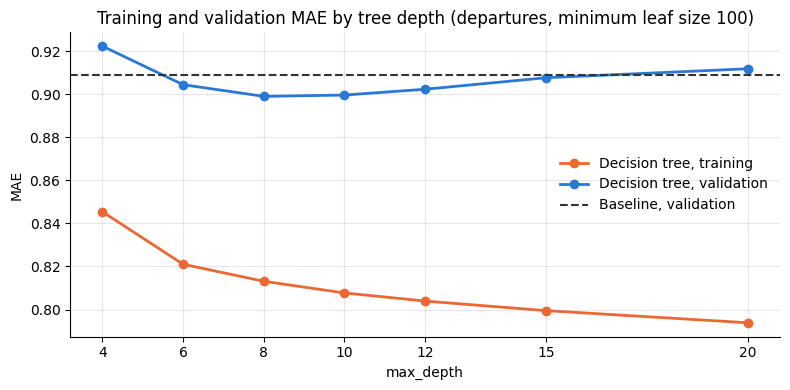

In [17]:
# Choose the tree depth and minimum leaf size on the Validation set
rows = []
for leaf in [100, 300, 1000]:
    for depth in [4, 6, 8, 10, 12, 15, 20]:
        tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf)
        tree.fit(train_x[TREE_FEATURES], train[TARGET])
        train_mae = mean_absolute_error(train[TARGET], tree.predict(train_x[TREE_FEATURES]))
        val_mae, val_rmse = evaluate(val[TARGET], tree.predict(val_x[TREE_FEATURES]))
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, "leaves": tree.get_n_leaves(),
                     "train MAE": train_mae, "val MAE": val_mae, "val RMSE": val_rmse, "gap": val_mae - train_mae})
grid = pd.DataFrame(rows)

baseline_train_mae = mean_absolute_error(train[TARGET], train_x["station_hour_dow_avg"])
baseline_val_mae = mean_absolute_error(val[TARGET], val_x["station_hour_dow_avg"])
print(f"Baseline: train MAE = {baseline_train_mae:.4f}, val MAE = {baseline_val_mae:.4f}, gap = {baseline_val_mae - baseline_train_mae:.4f}")
print("\nValidation MAE (rows: depth, columns: minimum leaf size)")
print(grid.pivot(index="max_depth", columns="min_samples_leaf", values="val MAE").round(4).to_string())
print("\nTraining MAE")
print(grid.pivot(index="max_depth", columns="min_samples_leaf", values="train MAE").round(4).to_string())
print("\nGap (validation MAE minus training MAE)")
print(grid.pivot(index="max_depth", columns="min_samples_leaf", values="gap").round(4).to_string())
lowest = grid.loc[grid["val MAE"].idxmin()]
print(f"\nLowest validation MAE: depth {int(lowest['max_depth'])}, minimum leaf size {int(lowest['min_samples_leaf'])} ({lowest['val MAE']:.4f})")

curve = grid[grid["min_samples_leaf"] == 100]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve["max_depth"], curve["train MAE"], marker="o", color="#eb6834", linewidth=2, label="Decision tree, training")
ax.plot(curve["max_depth"], curve["val MAE"], marker="o", color="#2a78d6", linewidth=2, label="Decision tree, validation")
ax.axhline(baseline_val_mae, color="#333333", linestyle="--", linewidth=1.5, label="Baseline, validation")
ax.set_title(f"Training and validation MAE by tree depth ({TARGET}, minimum leaf size 100)")
ax.set_xlabel("max_depth")
ax.set_ylabel("MAE")
ax.set_xticks(curve["max_depth"])
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**OBSERVATION**

The MAE for the Training set goes down as the depth increases. However, the MAE for the Validation set starts to go up after depth 8 or 10. From the raw values, the MAE on Validation is almost the same from 8 to 10 with just a tiny uptick.

This increasing gap between the MAE of the Training and Validation sets is sign of overfitting on the training data. Also, leaf count doesn't affect the result much at the same depth.

Therefore, we choose a tree depth of 8 with leaf count of 100 for the Decision tree as this is the last value where MAE of both the Training and Validation sets were still going down.

In [18]:
# settings we use from here on
TREE_DEPTH = 8
MIN_LEAF = 100

tree_model = DecisionTreeRegressor(max_depth=TREE_DEPTH, min_samples_leaf=MIN_LEAF).fit(train_x[TREE_FEATURES], train[TARGET])
val_res["tree"] = tree_model.predict(val_x[TREE_FEATURES])
print(f"Decision tree, new features (depth {TREE_DEPTH}) on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["tree"]))
print("\nFeature importance:")
print(pd.Series(tree_model.feature_importances_, index=TREE_FEATURES).sort_values(ascending=False).round(3).to_string())

Decision tree, new features (depth 8) on validation: MAE = 0.8991, RMSE = 1.7537

Feature importance:
station_hour_dow_avg    0.962
temp_c                  0.022
is_raining              0.006
precip_mm               0.005
hour_of_day             0.001
month                   0.001
day_of_week             0.001
new_station             0.001
weekend_or_holiday      0.001
prec_mm_prev_hr         0.000
year                    0.000


**D. Comparison of Models and Selection**

In [19]:
MODEL_NAMES = {"baseline_m4": "Baseline (M4)",
               "m4_linear": "M4 linear regression",
               "m4_tree": "M4 decision tree (depth 20)",
               "baseline": "Baseline, nearest stations",
               "linear": "Linear regression, new features",
               "tree": f"Decision tree, new features (depth {TREE_DEPTH})"}
COMPARE_WITH = {"baseline_m4": "baseline_m4", "m4_linear": "baseline_m4", "m4_tree": "baseline_m4",
                "baseline": "baseline", "linear": "baseline", "tree": "baseline"}

def score_table(results, columns):
    rows = []
    for column in columns:
        mae, rmse = evaluate(results["actual"], results[column])
        reference = evaluate(results["actual"], results[COMPARE_WITH[column]])[0]
        rows.append({"model": MODEL_NAMES[column], "MAE": mae, "RMSE": rmse,
                     "R2": r2_score(results["actual"], results[column]),
                     "mean error": (results[column] - results["actual"]).mean(),
                     "MAE vs its baseline (%)": (mae / reference - 1) * 100})
    return pd.DataFrame(rows).set_index("model")

print(f"===== {TARGET.upper()}: validation months (June to October 2024) =====")
print(score_table(val_res, list(MODEL_NAMES)).round(4).to_string())

saved[TARGET] = val_res.copy()

===== DEPARTURES: validation months (June to October 2024) =====
                                          MAE    RMSE      R2  mean error  MAE vs its baseline (%)
model                                                                                             
Baseline (M4)                          0.9323  1.7949  0.5711     -0.1806                   0.0000
M4 linear regression                   1.1860  2.1668  0.3750      0.0138                  27.2052
M4 decision tree (depth 20)            0.9582  1.8328  0.5528     -0.1219                   2.7680
Baseline, nearest stations             0.9091  1.7815  0.5775     -0.1935                   0.0000
Linear regression, new features        0.9556  1.7620  0.5867     -0.0739                   5.1154
Decision tree, new features (depth 8)  0.8991  1.7537  0.5906     -0.1595                  -1.1026


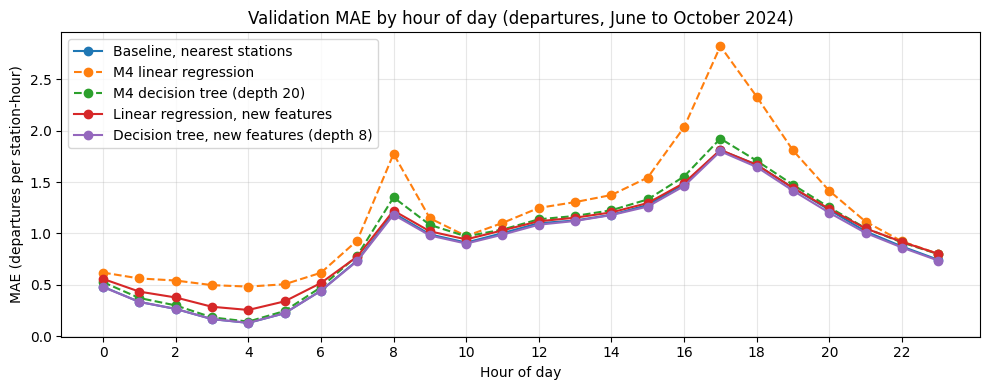

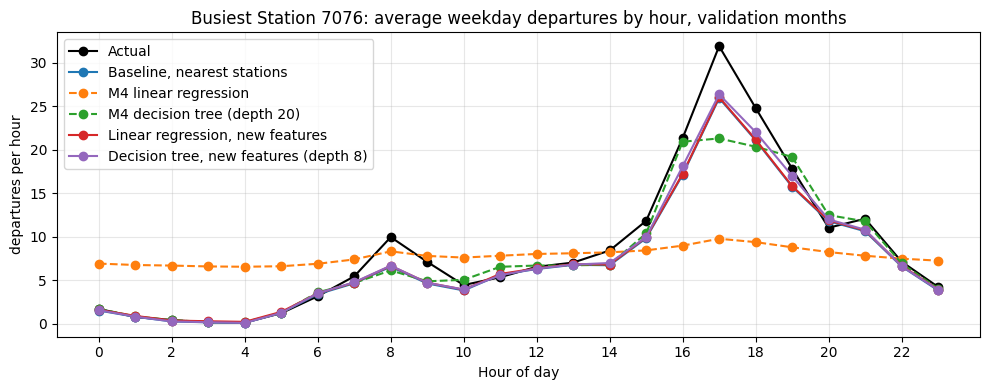

In [20]:
# which column in val_res belongs to which model name (the M4 models are drawn with dashed lines)
model_columns = {"Baseline, nearest stations": "baseline",
                 "M4 linear regression": "m4_linear",
                 "M4 decision tree (depth 20)": "m4_tree",
                 "Linear regression, new features": "linear",
                 f"Decision tree, new features (depth {TREE_DEPTH})": "tree"}
line_styles = ["--" if name.startswith("M4") else "-" for name in model_columns]
line_colors = [f"C{i}" for i in range(len(model_columns))]

# MAE by hour of day on validation, one line per model
by_hour = pd.DataFrame(index=range(24))
for name, column in model_columns.items():
    abs_error = (val_res[column] - val_res["actual"]).abs()
    by_hour[name] = abs_error.groupby(val["hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
by_hour.plot(ax=ax, marker="o", style=line_styles, color=line_colors)
ax.set_title(f"Validation MAE by hour of day ({TARGET}, June to October 2024)")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"MAE ({TARGET} per station-hour)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# the busiest station in training: average weekday profile, actual vs predicted
busiest_station = train.groupby("station_id")[TARGET].sum().idxmax()
is_busiest_weekday = (val["station_id"] == busiest_station) & (val["weekend_or_holiday"] == 0)

profile = pd.DataFrame(index=range(24))
profile["Actual"] = val_res.loc[is_busiest_weekday, "actual"].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()
for name, column in model_columns.items():
    profile[name] = val_res.loc[is_busiest_weekday, column].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, marker="o", style=["-"] + line_styles, color=["black"] + line_colors)
ax.set_title(f"Busiest Station {busiest_station}: average weekday {TARGET} by hour, validation months")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"{TARGET} per hour")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**E. Summary**

For the Regression Task (Departures), we created the baseline model (using simple averages), a linear regression model, and a decision tree model with hyperparameter-tuning of its depth from 4-20.

Both the original M4 models and the updated models with the new features and calculations using the nearest station averages for stations with no historical data were run and compared.

Based on the results above, the new Decision Tree with depth 8 beats the baseline on the Validation set. However, no models predicted the actual peak of the busiest station (see the graph of the busiest station's average weekday departures above).

The new features and calculations helped the Linear Regression model the most. Compared to the original M4 version, the new Linear Regression model is no longer almost a flat line but is now able to follow the shape of the station's average weekday departures.

**F. Final Model**

The new Decision Tree with depth 8 now just beats the Baseline model. At the evaluation run for this report, the MAE of the new Decision Tree(depth 8) is 0.8991 against 0.9091 of the Baseline model with the adjusted nearest station calculations. We will re-train this model in the Part 4 on the Training+Validation set and use the Test set to evaluate it.

#### 2. **Regression: Arrivals**

The Regression Models for Arrivals are the same as those for Departures but with a different target.

In [21]:
# Choose the target
TARGET = "arrivals"

val_res = pd.DataFrame()
val_res["station_id"] = val["station_id"]
val_res["hour_ts"] = val["hour_ts"]
val_res["actual"] = val[TARGET]

**A. Baseline Model**

In [22]:
val_res["baseline_m4"] = baseline_predict(train, val)             # as in M4 v1
val_res["baseline"] = baseline_predict(train, val, val_map)       # nearest stations
print("Baseline (M4v1 fallback) on validation:      MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["baseline_m4"]))
print("Baseline (nearest stations) on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["baseline"]))

Baseline (M4v1 fallback) on validation:      MAE = 0.9186, RMSE = 1.8204
Baseline (nearest stations) on validation: MAE = 0.8955, RMSE = 1.8080


**B. Linear Regression**

In [23]:
# feature tables for the Validation step (arrivals)
train_x = add_features(train, train)
val_x = add_features(train, val, val_map)
print("Feature tables ready:", train_x.shape, val_x.shape)

Feature tables ready: (3660096, 16) (3078048, 16)


In [24]:
# Original M4 v1 linear regression model without the new features
encoder_m4 = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                                ("numeric", "passthrough", NUMERIC)])
linear_m4 = LinearRegression().fit(encoder_m4.fit_transform(train[CATEGORICAL + NUMERIC]), train[TARGET])
val_res["m4_linear"] = np.clip(linear_m4.predict(encoder_m4.transform(val[CATEGORICAL + NUMERIC])), 0, None)
print("M4 linear regression on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["m4_linear"]))

# New version with the new features:
encoder, linear_model = fit_linear(train_x, train[TARGET])
val_res["linear"] = predict_linear(encoder, linear_model, val_x)
print("Linear regression, new features, on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["linear"]))
print("\nCoefficients of the numeric features:")
print(pd.Series(linear_model.coef_[-len(LINEAR_NUMERIC):], index=LINEAR_NUMERIC).round(4).to_string())

M4 linear regression on validation: MAE = 1.1868, RMSE = 2.3374
Linear regression, new features, on validation: MAE = 0.9414, RMSE = 1.7881

Coefficients of the numeric features:
year                    0.0186
weekend_or_holiday     -0.3401
temp_c                  0.0349
precip_mm              -0.0111
prec_mm_prev_hr        -0.0290
new_station            -0.4186
station_hour_dow_avg    0.9999
is_raining             -0.4796


**C. Decision Tree**

In [25]:
TREE_FEATURES = ["station_hour_dow_avg", "hour_of_day", "day_of_week", "month", "is_raining"] + NUMERIC

In [26]:
M4_TREE_FEATURES = ["station_avg", "hour_of_day", "day_of_week", "month"] + NUMERIC
station_avg = train.groupby("station_id")[TARGET].mean()
train_m4 = train.assign(station_avg=train["station_id"].map(station_avg))
val_m4 = val.assign(station_avg=val["station_id"].map(station_avg).fillna(train[TARGET].mean()))
tree_m4 = DecisionTreeRegressor(max_depth=20, min_samples_leaf=100).fit(train_m4[M4_TREE_FEATURES], train[TARGET])
val_res["m4_tree"] = tree_m4.predict(val_m4[M4_TREE_FEATURES])
print("M4 decision tree (depth 20) on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["m4_tree"]))
del train_m4, val_m4

M4 decision tree (depth 20) on validation: MAE = 0.9457, RMSE = 1.8739


Baseline: train MAE = 0.8289, val MAE = 0.8955, gap = 0.0667

Validation MAE (rows: depth, columns: minimum leaf size)
min_samples_leaf    100     300     1000
max_depth                               
4                 0.9113  0.9118  0.9127
6                 0.8898  0.8911  0.8932
8                 0.8847  0.8864  0.8903
10                0.8842  0.8860  0.8913
12                0.8875  0.8893  0.8948
15                0.8928  0.8927  0.8970
20                0.8970  0.8939  0.8970

Training MAE
min_samples_leaf    100     300     1000
max_depth                               
4                 0.8403  0.8410  0.8426
6                 0.8149  0.8158  0.8184
8                 0.8060  0.8076  0.8118
10                0.8009  0.8034  0.8090
12                0.7968  0.8007  0.8074
15                0.7923  0.7983  0.8068
20                0.7871  0.7969  0.8067

Gap (validation MAE minus training MAE)
min_samples_leaf    100     300     1000
max_depth                               
4     

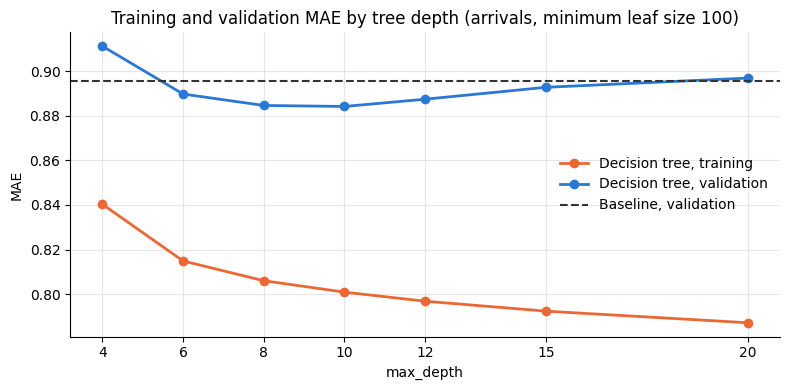

In [27]:
# Choose the tree depth and minimum leaf size on the Validation set
rows = []
for leaf in [100, 300, 1000]:
    for depth in [4, 6, 8, 10, 12, 15, 20]:
        tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf)
        tree.fit(train_x[TREE_FEATURES], train[TARGET])
        train_mae = mean_absolute_error(train[TARGET], tree.predict(train_x[TREE_FEATURES]))
        val_mae, val_rmse = evaluate(val[TARGET], tree.predict(val_x[TREE_FEATURES]))
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, "leaves": tree.get_n_leaves(),
                     "train MAE": train_mae, "val MAE": val_mae, "val RMSE": val_rmse, "gap": val_mae - train_mae})
grid = pd.DataFrame(rows)

baseline_train_mae = mean_absolute_error(train[TARGET], train_x["station_hour_dow_avg"])
baseline_val_mae = mean_absolute_error(val[TARGET], val_x["station_hour_dow_avg"])
print(f"Baseline: train MAE = {baseline_train_mae:.4f}, val MAE = {baseline_val_mae:.4f}, gap = {baseline_val_mae - baseline_train_mae:.4f}")
print("\nValidation MAE (rows: depth, columns: minimum leaf size)")
print(grid.pivot(index="max_depth", columns="min_samples_leaf", values="val MAE").round(4).to_string())
print("\nTraining MAE")
print(grid.pivot(index="max_depth", columns="min_samples_leaf", values="train MAE").round(4).to_string())
print("\nGap (validation MAE minus training MAE)")
print(grid.pivot(index="max_depth", columns="min_samples_leaf", values="gap").round(4).to_string())
lowest = grid.loc[grid["val MAE"].idxmin()]
print(f"\nLowest validation MAE: depth {int(lowest['max_depth'])}, minimum leaf size {int(lowest['min_samples_leaf'])} ({lowest['val MAE']:.4f})")

curve = grid[grid["min_samples_leaf"] == 100]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve["max_depth"], curve["train MAE"], marker="o", color="#eb6834", linewidth=2, label="Decision tree, training")
ax.plot(curve["max_depth"], curve["val MAE"], marker="o", color="#2a78d6", linewidth=2, label="Decision tree, validation")
ax.axhline(baseline_val_mae, color="#333333", linestyle="--", linewidth=1.5, label="Baseline, validation")
ax.set_title(f"Training and validation MAE by tree depth ({TARGET}, minimum leaf size 100)")
ax.set_xlabel("max_depth")
ax.set_ylabel("MAE")
ax.set_xticks(curve["max_depth"])
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**OBSERVATION**

Similar to the Regression model for departures, the MAE for the Training set goes down as the depth increases. The MAE for the Validation set starts to go up after depth 8 or 10.

We can choose a depth of either 8 or 10 for the arrivals regression model, since at depth 10, the trend for Validation set still went down slightly compared to depth 8. However, this was only a tiny decrease. The graphs for bothe the arrivals and departures show that the MAE for depths 8 and 10 are very close. To keep things simple, we choose a tree depth of 8 with leaf count of 100, similar to the Decision tree for departures.

At this value for both the arrivals and departures models, MAE of both the Training and Validation sets were still going down.

In [28]:
# settings we use from here on
TREE_DEPTH = 8
MIN_LEAF = 100

tree_model = DecisionTreeRegressor(max_depth=TREE_DEPTH, min_samples_leaf=MIN_LEAF).fit(train_x[TREE_FEATURES], train[TARGET])
val_res["tree"] = tree_model.predict(val_x[TREE_FEATURES])
print(f"Decision tree, new features (depth {TREE_DEPTH}) on validation: MAE = %.4f, RMSE = %.4f" % evaluate(val_res["actual"], val_res["tree"]))
print("\nFeature importance:")
print(pd.Series(tree_model.feature_importances_, index=TREE_FEATURES).sort_values(ascending=False).round(3).to_string())

Decision tree, new features (depth 8) on validation: MAE = 0.8847, RMSE = 1.7827

Feature importance:
station_hour_dow_avg    0.968
temp_c                  0.017
precip_mm               0.008
is_raining              0.004
month                   0.001
hour_of_day             0.001
weekend_or_holiday      0.001
new_station             0.000
prec_mm_prev_hr         0.000
day_of_week             0.000
year                    0.000


**D. Comparison of Models and Selection**

In [29]:
MODEL_NAMES = {"baseline_m4": "Baseline (M4)",
               "m4_linear": "M4 linear regression",
               "m4_tree": "M4 decision tree (depth 20)",
               "baseline": "Baseline, nearest stations",
               "linear": "Linear regression, new features",
               "tree": f"Decision tree, new features (depth {TREE_DEPTH})"}
COMPARE_WITH = {"baseline_m4": "baseline_m4", "m4_linear": "baseline_m4", "m4_tree": "baseline_m4",
                "baseline": "baseline", "linear": "baseline", "tree": "baseline"}

def score_table(results, columns):
    rows = []
    for column in columns:
        mae, rmse = evaluate(results["actual"], results[column])
        reference = evaluate(results["actual"], results[COMPARE_WITH[column]])[0]
        rows.append({"model": MODEL_NAMES[column], "MAE": mae, "RMSE": rmse,
                     "R2": r2_score(results["actual"], results[column]),
                     "mean error": (results[column] - results["actual"]).mean(),
                     "MAE vs its baseline (%)": (mae / reference - 1) * 100})
    return pd.DataFrame(rows).set_index("model")

print(f"===== {TARGET.upper()}: validation months (June to October 2024) =====")
print(score_table(val_res, list(MODEL_NAMES)).round(4).to_string())

saved[TARGET] = val_res.copy()

===== ARRIVALS: validation months (June to October 2024) =====
                                          MAE    RMSE      R2  mean error  MAE vs its baseline (%)
model                                                                                             
Baseline (M4)                          0.9186  1.8204  0.6060     -0.1806                   0.0000
M4 linear regression                   1.1868  2.3374  0.3505      0.0146                  29.2088
M4 decision tree (depth 20)            0.9457  1.8739  0.5825     -0.1221                   2.9562
Baseline, nearest stations             0.8955  1.8080  0.6114     -0.1924                   0.0000
Linear regression, new features        0.9414  1.7881  0.6199     -0.0731                   5.1157
Decision tree, new features (depth 8)  0.8847  1.7827  0.6222     -0.1593                  -1.2139


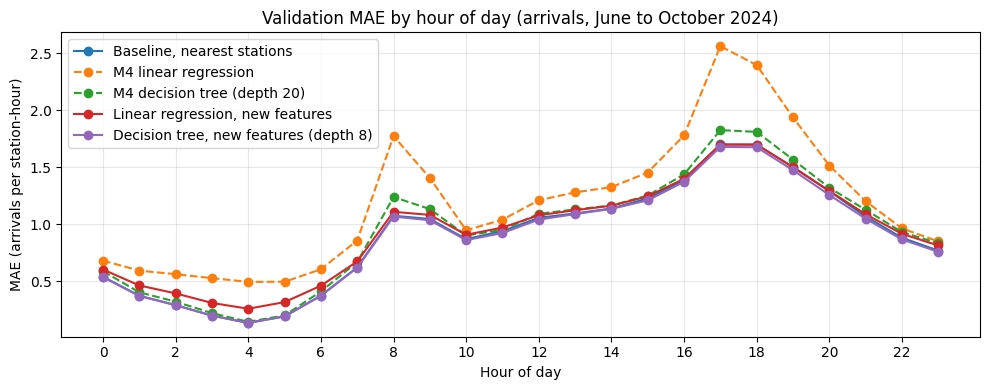

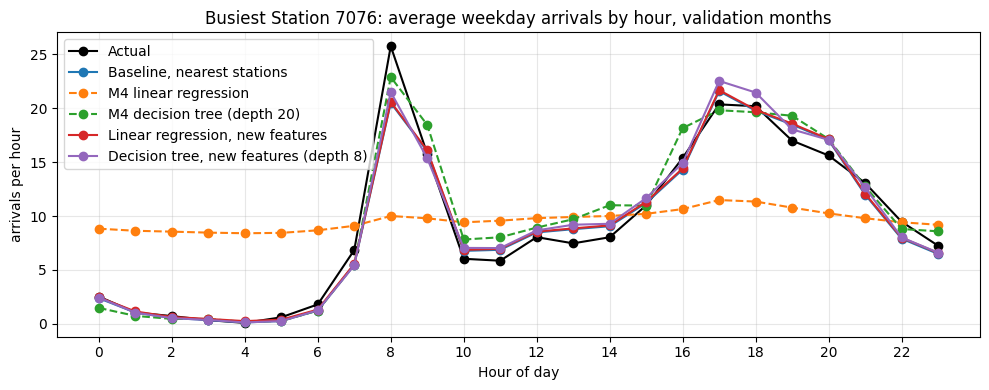

In [30]:
# which column in val_res belongs to which model name (the M4 models are drawn with dashed lines)
model_columns = {"Baseline, nearest stations": "baseline",
                 "M4 linear regression": "m4_linear",
                 "M4 decision tree (depth 20)": "m4_tree",
                 "Linear regression, new features": "linear",
                 f"Decision tree, new features (depth {TREE_DEPTH})": "tree"}
line_styles = ["--" if name.startswith("M4") else "-" for name in model_columns]
line_colors = [f"C{i}" for i in range(len(model_columns))]

# MAE by hour of day on validation, one line per model
by_hour = pd.DataFrame(index=range(24))
for name, column in model_columns.items():
    abs_error = (val_res[column] - val_res["actual"]).abs()
    by_hour[name] = abs_error.groupby(val["hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
by_hour.plot(ax=ax, marker="o", style=line_styles, color=line_colors)
ax.set_title(f"Validation MAE by hour of day ({TARGET}, June to October 2024)")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"MAE ({TARGET} per station-hour)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# the busiest station in training: average weekday profile, actual vs predicted
busiest_station = train.groupby("station_id")[TARGET].sum().idxmax()
is_busiest_weekday = (val["station_id"] == busiest_station) & (val["weekend_or_holiday"] == 0)

profile = pd.DataFrame(index=range(24))
profile["Actual"] = val_res.loc[is_busiest_weekday, "actual"].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()
for name, column in model_columns.items():
    profile[name] = val_res.loc[is_busiest_weekday, column].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, marker="o", style=["-"] + line_styles, color=["black"] + line_colors)
ax.set_title(f"Busiest Station {busiest_station}: average weekday {TARGET} by hour, validation months")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"{TARGET} per hour")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**E. Summary**

For the Regression Task (Arrivals), we created the baseline model (using simple averages), a linear regression model, and a decision tree model with hyperparameter-tuning of its depth from 4-20.

Both the original M4 models and the updated models with the new features and calculations using the nearest station averages for stations with no historical data were run and compared.

Based on the results above, the new Decision Tree with depth 8 beats the baseline on the Validation set. However, no models predicted the actual peak of the busiest station at 8AM (see the graph of the busiest station's average weekday arrivals above).

The new features and calculations helped the Linear Regression model the most. Compared to the original M4 version, the new Linear Regression model is no longer almost a flat line but is now able to follow the shape of the station's average weekday arrivals.

These results are similar to the results for the departures regression model.

**F. Final Model**

The results being the same as for the Departures, we will also select the Decision tree as our final model for the Regression task for Arrivals.

### Classification Model (Classify stations by Demand)

#### 1. **Classification: Low/Medium/High Demand**

Code for the logistic regression and kNN models with performance metrics included:

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load preprocessed classification table
cls_data = pd.read_parquet(f"{PROCESSED}/classification_station_month_may_oct.parquet")

FEATURES = ["monthly_volume", "was_flagged_new", "first_year", "first_month"]
DEMAND_LABELS = ["Low", "Medium", "High"]

train_df = cls_data[cls_data["split"] == "train"]
val_df = cls_data[cls_data["split"] == "val"]
test_df = cls_data[cls_data["split"] == "test"]

X_train_raw, y_train = train_df[FEATURES], train_df["target"]
X_val_raw, y_val = val_df[FEATURES], val_df["target"]
X_test_raw, y_test = test_df[FEATURES], test_df["target"]

# -------------------------------------------------------------
# STEP 1: TRAIN & COMPARE ON VALIDATION SET
# -------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)

log_reg = LogisticRegression(solver="lbfgs", max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

knn = KNeighborsClassifier(n_neighbors=5, weights="uniform")
knn.fit(X_train_scaled, y_train)

for name, model in [("Logistic Regression", log_reg), ("k-Nearest Neighbors (k=5)", knn)]:
    print(f"\n==================== {name.upper()} (TRAIN vs. VAL) ====================")
    for X_split, y_split, split_name in [(X_train_scaled, y_train, "Train"), (X_val_scaled, y_val, "Validation")]:
        preds = model.predict(X_split)
        print(f"--- {split_name} Accuracy: {accuracy_score(y_split, preds):.4f} ---")
        print(classification_report(y_split, preds, target_names=DEMAND_LABELS, zero_division=0))

# -------------------------------------------------------------
# STEP 2: RETRAIN ON TRAIN + VALIDATION & EVALUATE ON TEST SET
# -------------------------------------------------------------
print("\n==================== FINAL TEST EVALUATION (TRAIN+VAL -> TEST) ====================")
X_trainval_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
y_trainval = pd.concat([y_train, y_val], ignore_index=True)

final_scaler = StandardScaler()
X_trainval_scaled = final_scaler.fit_transform(X_trainval_raw)
X_test_scaled = final_scaler.transform(X_test_raw)

final_log_reg = LogisticRegression(solver="lbfgs", max_iter=1000)
final_log_reg.fit(X_trainval_scaled, y_trainval)

final_knn = KNeighborsClassifier(n_neighbors=5, weights="uniform")
final_knn.fit(X_trainval_scaled, y_trainval)

for name, model in [("Logistic Regression", final_log_reg), ("k-Nearest Neighbors (k=5)", final_knn)]:
    test_preds = model.predict(X_test_scaled)
    print(f"\n--- Final Test Set: {name} ---")
    print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f}")
    print(classification_report(y_test, test_preds, target_names=DEMAND_LABELS, zero_division=0))



==================== LOGISTIC REGRESSION (TRAIN vs. VAL) ====================
--- Train Accuracy: 0.9171 ---
              precision    recall  f1-score   support

         Low       0.92      0.95      0.94      1399
      Medium       0.89      0.87      0.88      1740
        High       0.94      0.93      0.94      1817

    accuracy                           0.92      4956
   macro avg       0.92      0.92      0.92      4956
weighted avg       0.92      0.92      0.92      4956

--- Validation Accuracy: 0.8765 ---
              precision    recall  f1-score   support

         Low       0.95      0.90      0.92      1354
      Medium       0.84      0.77      0.81      1316
        High       0.84      0.96      0.90      1323

    accuracy                           0.88      3993
   macro avg       0.88      0.88      0.88      3993
weighted avg       0.88      0.88      0.88      3993


==================== K-NEAREST NEIGHBORS (K=5) (TRAIN vs. VAL) ====================
--- Tra

As we can see from the metrics provided above, both models do a good job at classifying the stations as low, medium and high. Both models porvide good accuracy, precision, recall and f1-score for each of our targets. Even though both models predict our targets well, we decided to move forward with the logistic regression model.

We chose this model because even though the difference in the performance metrics is very similar to that of the kNN model, we will not need to do standardization on our logistic regression model like we would need to for the kNN model. Standardizing the data can lead to a more complex model, which can result in overfitting our data, leading to a model that is too accurate as it can memorize the training data.

## Part 4: Model Evaluation & Analytical Depth

### Regression

Re-train the selected model (new Decision tree, depth of 8) on Training+Validation (all of 2023-2024) and evaluate on Test (2025):

In [32]:
# Helper functions for the evaluation of the regression models.
# They are defined once and used for both targets. Like the functions in Part 3, they read TARGET,
# which is set in the cell that calls them.
GROUP_ORDER = ["Low", "Medium", "High", "No history"]
RAIN_ORDER = ["Dry", "Light rain", "Heavy rain"]
LINES = [("actual", "Actual", "#333333", "-", 2.5),
         ("baseline", "Baseline", "#2a78d6", "--", 2),
         ("linear", "Linear regression", "#eb6834", "-", 2),
         ("tree", "Decision tree", "#1baf7a", "-", 2)]
BAR_MODELS = [("linear", "Linear regression", "#eb6834"), ("tree", "Decision tree", "#1baf7a")]   # same colours as the line graphs
pd.set_option("display.width", 250)

# Demand level of each station, with the same rule as the classification task (M4 Part 1.3.7):
# training departures per operating day, cut into thirds of the training stations (departures also when TARGET is arrivals)
per_station = train.groupby("station_id")["departures"].agg(total="sum", hours="size")
per_station = per_station[per_station["total"] > 0]          # the classification table needs at least 1 departure
per_station["demand_rate"] = per_station["total"] / (per_station["hours"] / 24)
c1, c2 = np.quantile(per_station["demand_rate"], [1/3, 2/3])
print(f"Cutoffs from the training months: Low <= {c1:.2f} | Medium <= {c2:.2f} | High > {c2:.2f} departures per day")
per_station["demand_level"] = pd.cut(per_station["demand_rate"], bins=[-np.inf, c1, c2, np.inf], labels=["Low", "Medium", "High"]).astype(str)

# Training + Validation (all of May to October 2023 and 2024), used to refit the final model for the Test set.
# Station groups for 2025: demand level from all of 2023-2024 with the same cutoffs (c1, c2).
fit_data = pd.concat([train, val], ignore_index=True)
test_map, test_no_history = build_neighbour_map(fit_data, test)
history = fit_data.groupby("station_id")["departures"].agg(total="sum", hours="size")
history["level"] = pd.cut(history["total"] / (history["hours"] / 24), bins=[-np.inf, c1, c2, np.inf], labels=["Low", "Medium", "High"]).astype(str)

# MAE and mean error of the final models for each value of a column
def compare(results, by, order=None, models=("linear", "tree")):
    table = pd.DataFrame()
    table["station-hours"] = results.groupby(by).size()
    table["average actual"] = results.groupby(by)["actual"].mean()
    table["MAE Baseline"] = (results["baseline"] - results["actual"]).abs().groupby(results[by]).mean()
    for column in models:
        short = "Linear" if column == "linear" else "Tree"
        table["MAE " + short] = (results[column] - results["actual"]).abs().groupby(results[by]).mean()
        table[short + " vs baseline (%)"] = (table["MAE " + short] / table["MAE Baseline"] - 1) * 100
    table["mean error Baseline"] = (results["baseline"] - results["actual"]).groupby(results[by]).mean()
    for column in models:
        short = "Linear" if column == "linear" else "Tree"
        table["mean error " + short] = (results[column] - results["actual"]).groupby(results[by]).mean()
    return table.reindex(order) if order else table

# Rain labels for every row.
#   rain_hour: rain in that hour.         Dry = 0 mm, Light rain = up to 2 mm, Heavy rain = more than 2 mm
#   rain_day : total rain on that date.   Dry = 0 mm, Light rain = under 5 mm, Heavy rain = 5 mm or more
def add_rain_labels(results, source):
    out = results.copy()
    out["hour_of_day"] = source["hour_of_day"].to_numpy()
    out["month"] = source["month"].to_numpy()
    out["precip_mm"] = source["precip_mm"].to_numpy()
    out["date"] = out["hour_ts"].dt.normalize()
    out["rain_hour"] = np.select([out["precip_mm"] == 0, out["precip_mm"] <= 2], ["Dry", "Light rain"], "Heavy rain")

    # the weather is one city-wide series, so one row per hour is enough to get the daily total
    hours = out.drop_duplicates("hour_ts")
    daily = hours.groupby("date")["precip_mm"].agg(rain_mm="sum", wet_hours=lambda s: (s > 0).sum()).reset_index()
    daily["rain_day"] = np.select([daily["rain_mm"] == 0, daily["rain_mm"] < 5], ["Dry", "Light rain"], "Heavy rain")
    out = out.merge(daily[["date", "rain_day"]], on="date", how="left")
    return out, daily

# MAE of a model compared with the baseline (%), for each station group and rain condition.
# Below 0 means the model's errors are smaller than the baseline's.
def mae_vs_baseline(results, column):
    keys = [results["group"], results["rain_hour"]]
    model_mae = (results[column] - results["actual"]).abs().groupby(keys).mean().unstack()
    baseline_mae = (results["baseline"] - results["actual"]).abs().groupby(keys).mean().unstack()
    return ((model_mae / baseline_mae - 1) * 100).reindex(index=GROUP_ORDER, columns=RAIN_ORDER)

# Bar graph of mae_vs_baseline: one panel for each rain condition, one pair of bars for each station group
def plot_change_bars(results, period):
    change = {column: mae_vs_baseline(results, column) for column, label, color in BAR_MODELS}
    hours = results.groupby("rain_hour").size().reindex(RAIN_ORDER)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    positions = np.arange(len(GROUP_ORDER))
    width = 0.38
    for ax, rain in zip(axes, RAIN_ORDER):
        for k, (column, label, color) in enumerate(BAR_MODELS):
            values = change[column][rain]
            bars = ax.bar(positions + (k - 0.5) * width, values, width=width - 0.03, color=color, label=label)
            for bar, value in zip(bars, values):
                ax.annotate(f"{value:+.0f}%", (bar.get_x() + bar.get_width() / 2, value), xytext=(0, -11 if value < 0 else 3),
                            textcoords="offset points", ha="center", fontsize=8, color="#333333")
        ax.axhline(0, color="#333333", linewidth=1)
        ax.set_title(f"{rain} hours ({hours[rain] / hours.sum() * 100:.0f}% of station-hours)")
        ax.set_xticks(positions)
        ax.set_xticklabels(GROUP_ORDER)
        ax.set_xlabel("Station group")
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("MAE compared with the baseline (%)")
    axes[0].legend(frameon=False, loc="upper right")
    fig.suptitle(f"MAE of each model compared with the baseline, by rain and station group ({TARGET}, {period}). Below 0 = smaller errors than the baseline")
    plt.tight_layout()
    plt.show()

# Average per station-hour by hour of day, for all days of each type
def plot_day_profiles(results, days, lines, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, day_type in zip(axes, RAIN_ORDER):
        rows = results[results["rain_day"] == day_type]
        profile = rows.groupby("hour_of_day")[[line[0] for line in lines]].mean()
        for column, label, color, style, width in lines:
            ax.plot(profile.index, profile[column], label=label, color=color, linestyle=style, linewidth=width)
        ax.set_title(f"{day_type} days ({(days['rain_day'] == day_type).sum()} days)")
        ax.set_xlabel("Hour of day")
        ax.set_xticks(range(0, 24, 2))
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel(f"Average {TARGET} per station-hour")
    axes[0].legend(frameon=False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# Validation results of the models from Part 3 (saved[TARGET]): by station group, month and rain, and on busy hours
def validation_report():
    val_rain, val_days = add_rain_labels(saved[TARGET], val)
    val_rain["group"] = val_rain["station_id"].map(per_station["demand_level"])
    val_rain.loc[~val_rain["station_id"].isin(set(train["station_id"])), "group"] = "No history"
    val_rain["group"] = val_rain["group"].fillna("Low")     # training stations with zero departures

    print(f"===== {TARGET.upper()}: validation months (June to October 2024). Baseline = baseline with nearest stations =====")
    print("\nValidation MAE by station group:")
    print(val_rain.groupby("group")["station_id"].nunique().reindex(GROUP_ORDER).rename("stations").to_frame().T.to_string())
    print(compare(val_rain, "group", GROUP_ORDER).round(3).T.to_string())

    # effect of the nearest stations rule on the stations with no history
    no_hist = val_rain[val_rain["group"] == "No history"]
    print(f"\nStations with no history: baseline MAE with the M4 fallback = {evaluate(no_hist['actual'], no_hist['baseline_m4'])[0]:.3f}, "
          f"with nearest stations = {evaluate(no_hist['actual'], no_hist['baseline'])[0]:.3f}")

    print("\nValidation MAE by month:")
    print(compare(val_rain, "month").round(3).T.to_string())

    print("\nValidation days by type:")
    print(val_days.groupby("rain_day").agg(days=("date", "size"), average_rain_mm=("rain_mm", "mean"),
                                           average_wet_hours=("wet_hours", "mean")).reindex(RAIN_ORDER).round(1).to_string())
    print("\nValidation MAE by rain in the HOUR:")
    print(compare(val_rain, "rain_hour", RAIN_ORDER).round(3).T.to_string())

    # busy hours
    actual = val_rain["actual"]
    busy = actual >= 10
    print(f"\nValidation hours with 10 or more {TARGET}: {busy.sum():,} ({busy.mean() * 100:.1f}% of station-hours)")
    for column, label in [("baseline", "Baseline, nearest stations"), ("linear", "Linear regression, new features"),
                          ("tree", f"Decision tree, new features (depth {TREE_DEPTH})")]:
        print(f"  {label}: mean error on these hours = {(val_rain[column] - actual)[busy].mean():.2f}")
    print(f"Linear regression predictions set to 0 (below zero before clipping): {(val_rain['linear'] == 0).mean() * 100:.1f}%")

    # each model against the baseline for each station group and rain condition
    print("\nStation-hours in each group and rain condition:")
    print(val_rain.groupby(["group", "rain_hour"]).size().unstack().reindex(index=GROUP_ORDER, columns=RAIN_ORDER).to_string())
    print("\nDecision tree: MAE compared with the baseline (%)")
    print(mae_vs_baseline(val_rain, "tree").round(1).to_string())
    print("\nLinear regression: MAE compared with the baseline (%)")
    print(mae_vs_baseline(val_rain, "linear").round(1).to_string())
    plot_change_bars(val_rain, "validation months")

# Final model: decision tree with the settings chosen in Part 3, refitted on Training + Validation, tested on 2025
def test_report():
    print("Test stations:", test["station_id"].nunique(), " with no history:", len(test_no_history),
          " of these with coordinates:", test_map["station_id"].nunique())
    fit_x = add_features(fit_data, fit_data)
    test_x = add_features(fit_data, test, test_map)
    final_tree = DecisionTreeRegressor(max_depth=TREE_DEPTH, min_samples_leaf=MIN_LEAF)
    final_tree.fit(fit_x[TREE_FEATURES], fit_data[TARGET])

    test_res = pd.DataFrame()
    test_res["station_id"] = test["station_id"]
    test_res["hour_ts"] = test["hour_ts"]
    test_res["actual"] = test[TARGET]
    test_res["baseline_m4"] = baseline_predict(fit_data, test)            # baseline as in M4, for reference
    test_res["baseline"] = test_x["station_hour_dow_avg"].to_numpy()      # baseline with nearest stations
    test_res["tree"] = final_tree.predict(test_x[TREE_FEATURES])

    print(f"\n===== {TARGET.upper()}: test months (May to October 2025), {len(test):,} station-hours =====")
    print(score_table(test_res, ["baseline_m4", "baseline", "tree"]).round(4).to_string())
    fit_mae = mean_absolute_error(fit_data[TARGET], final_tree.predict(fit_x[TREE_FEATURES]))
    test_mae = mean_absolute_error(test_res["actual"], test_res["tree"])
    print(f"\nFinal tree: MAE on Training + Validation = {fit_mae:.4f}, on Test = {test_mae:.4f}, leaves = {final_tree.get_n_leaves()}")
    print("\nFeature importance of the final tree:")
    print(pd.Series(final_tree.feature_importances_, index=TREE_FEATURES).sort_values(ascending=False).round(3).to_string())

    # the same test result by month, station group and rain
    test_rain, test_days = add_rain_labels(test_res, test)
    test_rain["group"] = test_rain["station_id"].map(history["level"]).fillna("No history")
    print("\nBaseline = baseline with nearest stations.")
    print("\nTest MAE by month:")
    print(compare(test_rain, "month", models=("tree",)).round(3).to_string())
    print("\nTest MAE by station group:")
    print(test_rain.groupby("group")["station_id"].nunique().reindex(GROUP_ORDER).rename("stations").to_frame().T.to_string())
    print(compare(test_rain, "group", GROUP_ORDER, models=("tree",)).round(3).to_string())
    print("\nTest days by type:")
    print(test_days.groupby("rain_day").size().reindex(RAIN_ORDER).rename("days").to_frame().T.to_string())
    print("\nTest MAE by rain in the hour:")
    print(compare(test_rain, "rain_hour", RAIN_ORDER, models=("tree",)).round(3).to_string())
    print("\nTest MAE by rain on the day:")
    print(compare(test_rain, "rain_day", RAIN_ORDER, models=("tree",)).round(3).to_string())

    final_lines = [line for line in LINES if line[0] != "linear"]
    plot_day_profiles(test_rain, test_days, final_lines, f"Final model: actual vs predicted {TARGET} by type of day, test months (May to October 2025)")

Cutoffs from the training months: Low <= 9.03 | Medium <= 35.81 | High > 35.81 departures per day


#### **1. Regression: Departures**

===== DEPARTURES: validation months (June to October 2024). Baseline = baseline with nearest stations =====

Validation MAE by station group:
group     Low  Medium  High  No history
stations  273     266   266          58
group                          Low      Medium        High  No history
station-hours           995880.000  966432.000  971592.000  144144.000
average actual               0.203       1.021       3.056       0.727
MAE Baseline                 0.274       0.828       1.658       0.790
MAE Linear                   0.396       0.855       1.653       0.793
Linear vs baseline (%)      44.259       3.276      -0.278       0.400
MAE Tree                     0.276       0.823       1.633       0.764
Tree vs baseline (%)         0.617      -0.554      -1.510      -3.315
mean error Baseline         -0.035      -0.204      -0.419       0.302
mean error Linear            0.133      -0.095      -0.325       0.329
mean error Tree             -0.028      -0.177      -0.342       0.2

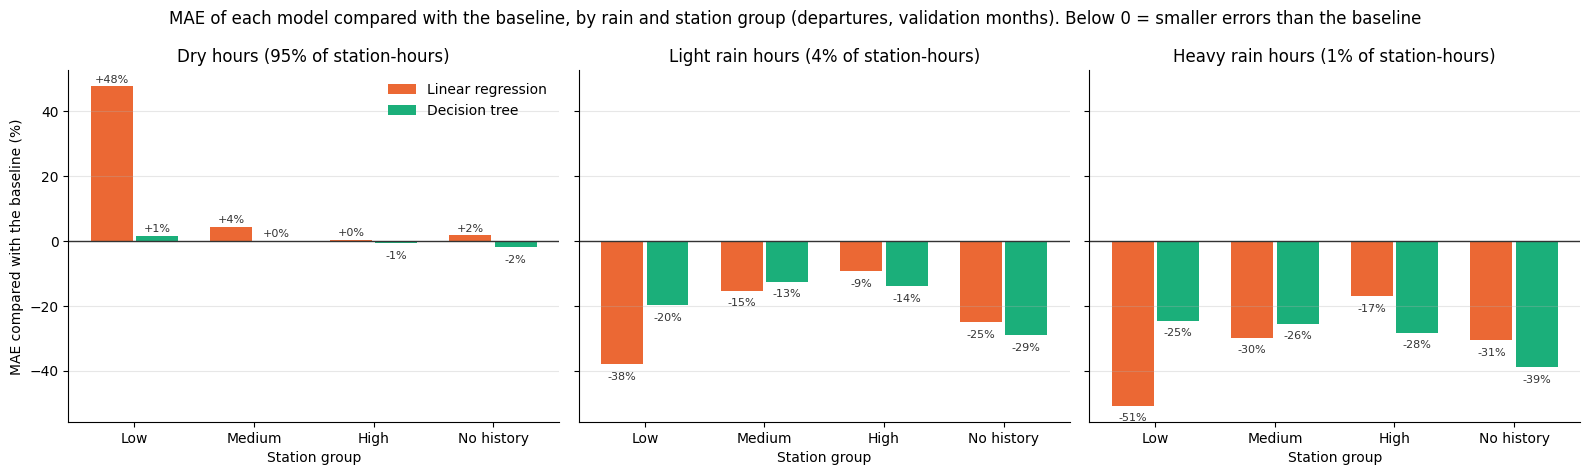

In [33]:
TARGET = "departures"
validation_report()

Test stations: 1032  with no history: 177  of these with coordinates: 157

===== DEPARTURES: test months (May to October 2025), 4,220,184 station-hours =====
                                          MAE    RMSE      R2  mean error  MAE vs its baseline (%)
model                                                                                             
Baseline (M4)                          1.0527  2.4264  0.4350     -0.1473                   0.0000
Baseline, nearest stations             0.9682  2.3342  0.4771     -0.2098                   0.0000
Decision tree, new features (depth 8)  0.9391  2.2841  0.4993     -0.2215                  -3.0023

Final tree: MAE on Training + Validation = 0.8399, on Test = 0.9391, leaves = 244

Feature importance of the final tree:
station_hour_dow_avg    0.967
temp_c                  0.014
precip_mm               0.007
is_raining              0.004
month                   0.003
year                    0.001
new_station             0.001
hour_of_day    

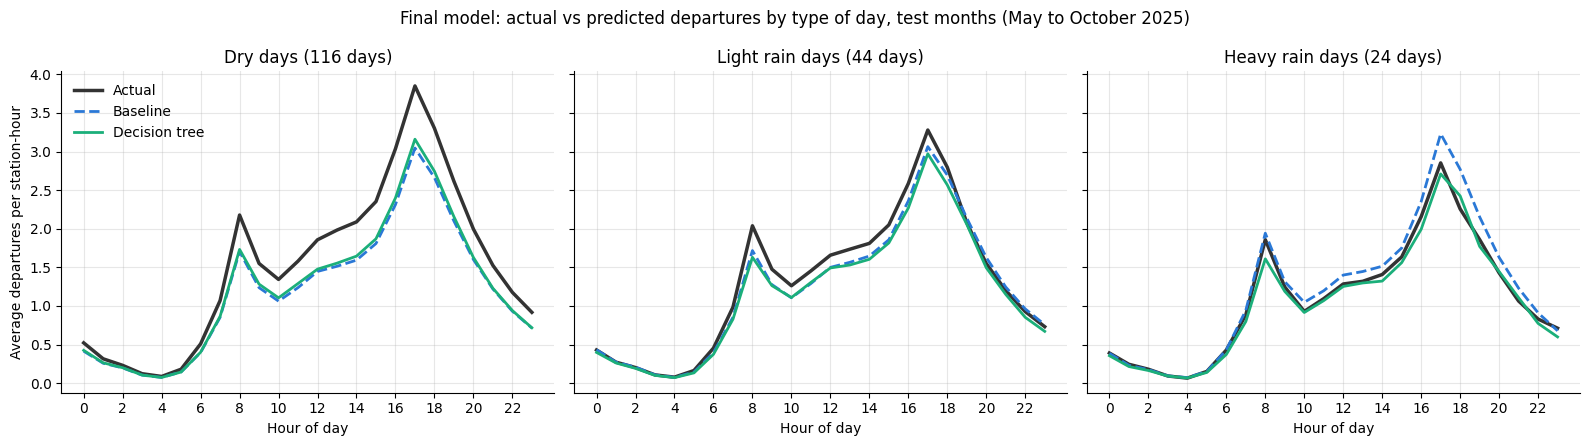

In [34]:
test_report()

The following analysis is based on the results in Part 3 (Regression: Departures) and the results above:

1. **Interpretation:**
    - **From Part 3 (D, comparison table):** On the Validation set, the MAE is 0.909 for the baseline, 0.956 for linear regression and 0.899 for the decision tree. R² is ~0.58 for the baseline and ~0.59 for linear regression and the decision tree. For the first version of our models (the M4 rows), the R² of linear regression was ~0.38, and the decision tree (MAE 0.958) was worse than its baseline (MAE 0.932).
    - **From Part 4 (Validation MAE by month):** The average station-hour has only ~1.3 to 1.5 departures.
    - **Overall:** All three models are still wrong by ~1 departure per station per hour on average, which is quite large compared to the average of ~1.4 departures. They explain a bit less than 60% of the variation in the bike share ridership data. Linear regression improved the most, and the new decision tree is now slightly better than the baseline instead of slightly worse if we consider only the averages.

2. **Training vs validation vs test:**
    - **From Part 3 (C, depth tables):** For the new decision tree (depth 8), the MAE is 0.81 on the Training set and 0.90 on the Validation set. For the baseline, it is 0.84 and 0.91.
    - **From Part 4 (test results):** After retraining on Training + Validation, the MAE of the decision tree is 0.84 on that data and 0.94 on the Test set. The baseline has an MAE of 0.97 on the Test set.
    - **Overall:** The error increases from Training to Validation to Test for both the decision tree and the baseline. This means that higher error on the later data is not due to poor generalization of the decision tree itself but is likely caused by the new stations in the later periods, which have no history. As the station group table, all models predict too high compared to the actual volume for new stations.

3. **Bias vs variance:**
    - **From Part 3 (B and D):** With the new features, the MAE of linear regression went down from 1.19 to 0.96.
    - **From Part 3 (C, depth tables):** For the decision tree, the gap between training and validation MAE grows from ~0.08 at depth 4 to ~0.12 at depth 20. The validation MAE stops improving after depth 8 to 10, and at depth 20 the tree is worse than the baseline (0.912 against 0.909). At depth 8 the gap (0.086) is close to the gap of the baseline itself (0.073).
    - **From Part 4 (Validation MAE by station group):** Linear regression is much worse than the baseline for Low demand stations (+44%).
    - **Overall:** The first version of the linear regression model had high bias, since it gave every station the same hourly shape. Adding the feature `station_hour_dow_avg` has it start from each station's own pattern, so the bias is smaller. It is still an additive model: the same correction for rain or temperature is applied to every station, whether it is busy or quiet, which is why it is too high for Low demand stations. For the decision tree, the variance goes up with the depth and overfitting begins to be observed after a depth of around 8-10. This is different from the first version, where the validation MAE was still improving at depth 20.

4. **Error analysis (from Part 4, validation results):**
    - **Busy hours (hours with 10 or more departures):** These are 2.2% of the station-hours. The baseline is too low by ~6.3 departures, linear regression by ~6.2 and the decision tree by ~5.9.
    - **Demand level (Validation MAE by station group):** The decision tree is better than the baseline for Medium (-0.6%), High (-1.5%) and No history (-3.3%) stations, and about the same for Low demand stations (+0.6%).
    - **Rain (Validation MAE by rain in the hour):** The baseline is too high in the hours with rain (mean error +0.32 in light rain and +0.58 in heavy rain). The decision tree has ~15% lower MAE than the baseline in light rain hours and ~28% lower in heavy rain hours. In dry hours it is about the same as the baseline (-0.3%).
    - **Rain and demand level together (bar graph):** Only ~5% of the hours have rain. Linear regression is better than the decision tree in the rain for Low demand stations, but it is much worse than the baseline for the same stations in dry hours.
    - **Stations with no history:** Using the 3 nearest stations lowers the baseline MAE for these stations from 1.29 to 0.79. The predictions are still too high (mean error ~+0.3 in the station group table), so the new stations were quieter than the stations near them.
    - **Predictions below zero:** ~9% of the linear regression predictions were below zero before we set them to 0. In the first version of this report it was ~20%.
    - **Overall:** The baseline predicts the same number whether it rains or not, so the decision tree improves on it mostly in the hours with rain. Since most hours are dry, the overall improvement is small. All models still predict too low compared to the actual volume on busy hours.

5. **Robustness (from Part 4):** We checked whether the decision tree is better than the baseline in every part of the data, or only in some parts.
    - **By month on the Validation set:** The decision tree has a lower MAE than the baseline in each of the five validation months (0.7% to 1.8% lower). Linear regression has a lower MAE than the baseline only in October.
    - **On the Test set:** The decision tree has a lower MAE than the baseline in each of the six test months (0.4% to 10.5% lower), for each station group (0.5% to 4.4% lower), and in dry, light rain and heavy rain hours. The biggest difference is in May 2025, because the baseline predicted too high in that month (by 0.21 departures per station-hour on average).
    - **Overall:** The decision tree performed better than the baseline in each part we checked, so the result does not come from one month or one group of stations. Results differ slightly between runs but remain in the same ranges.

**Final model on the Test set (May to October 2025), from Part 4 (test results)**

| Model (trained on Training + Validation) | MAE | RMSE | R² |
|--|--|--|--|
| Baseline (first version) | 1.05 | 2.43 | 0.44 |
| Baseline, nearest stations | 0.97 | 2.33 | 0.48 |
| Decision tree, new features (depth 8) | 0.94 | 2.28 | 0.50 |

6. The decision tree is ~3.0% better than the baseline on the Test set (MAE 0.939 vs 0.968), where both use the nearest stations for stations with no history. This meets our success criterion from 1.2 (lower Test MAE than the baseline) for departures. In the first version of this report, the decision tree was ~1.2% behind the baseline. The biggest improvement comes from the nearest stations rule: it lowers the Test MAE of the baseline itself from 1.05 to 0.97, because the Test set has 177 stations with no history (157 of these have coordinates).

#### **2. Regression: Arrivals**

===== ARRIVALS: validation months (June to October 2024). Baseline = baseline with nearest stations =====

Validation MAE by station group:
group     Low  Medium  High  No history
stations  273     266   266          58
group                          Low      Medium        High  No history
station-hours           995880.000  966432.000  971592.000  144144.000
average actual               0.201       0.994       3.079       0.743
MAE Baseline                 0.267       0.801       1.647       0.803
MAE Linear                   0.388       0.828       1.642       0.804
Linear vs baseline (%)      45.079       3.392      -0.343       0.192
MAE Tree                     0.269       0.795       1.619       0.792
Tree vs baseline (%)         0.551      -0.751      -1.718      -1.395
mean error Baseline         -0.042      -0.198      -0.415       0.309
mean error Linear            0.126      -0.089      -0.321       0.334
mean error Tree             -0.036      -0.174      -0.340       0.305

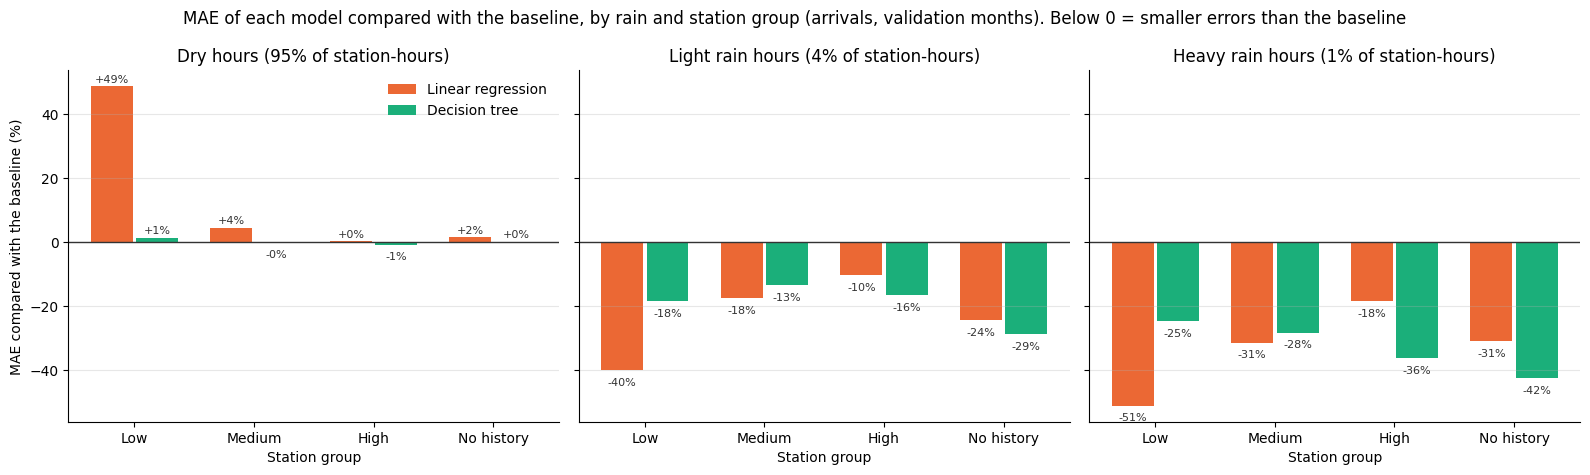

In [35]:
TARGET = "arrivals"
validation_report()

Test stations: 1032  with no history: 177  of these with coordinates: 157

===== ARRIVALS: test months (May to October 2025), 4,220,184 station-hours =====
                                          MAE    RMSE      R2  mean error  MAE vs its baseline (%)
model                                                                                             
Baseline (M4)                          1.0397  2.4416  0.4826     -0.1473                   0.0000
Baseline, nearest stations             0.9562  2.3523  0.5198     -0.2037                   0.0000
Decision tree, new features (depth 8)  0.9253  2.3066  0.5382     -0.2153                  -3.2306

Final tree: MAE on Training + Validation = 0.8299, on Test = 0.9253, leaves = 223

Feature importance of the final tree:
station_hour_dow_avg    0.970
temp_c                  0.010
precip_mm               0.009
is_raining              0.003
month                   0.003
year                    0.001
hour_of_day             0.001
new_station      

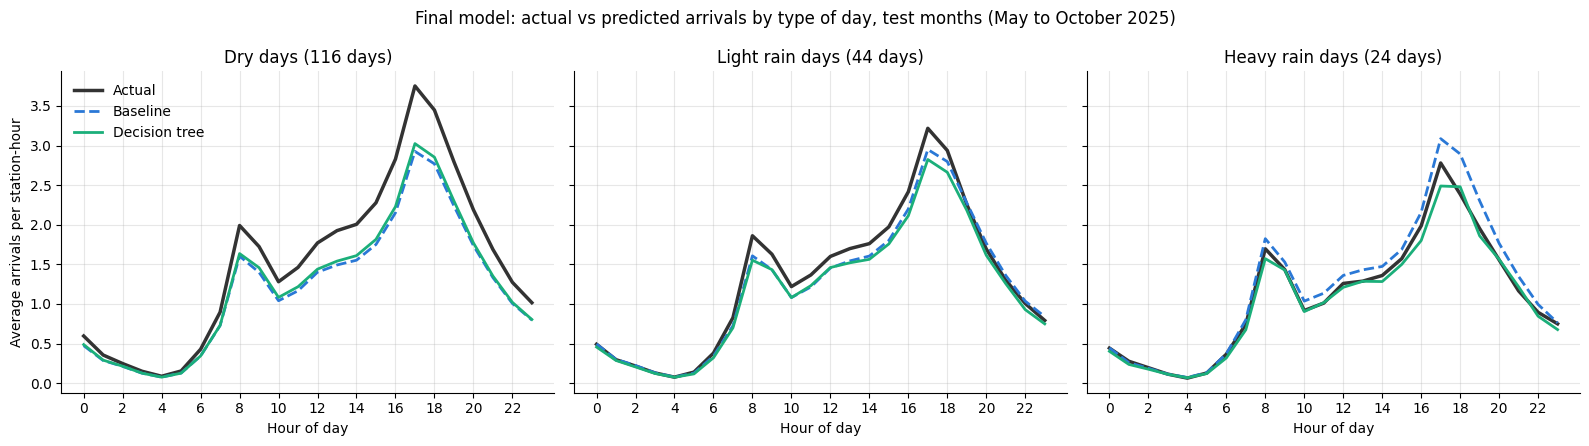

In [36]:
test_report()

The following analysis is based on the results in Part 3 (Regression: Arrivals) and the results above. The demand levels of the stations are based on departures, the same as in the classification task.

1. **Interpretation:**
    - **From Part 3 (D, comparison table):** On the Validation set, the MAE is 0.896 for the baseline, 0.941 for linear regression and 0.885 for the decision tree. R² is ~0.61 for the baseline and ~0.62 for linear regression and the decision tree. For the first version of our models (the M4 rows), the R² of linear regression was ~0.35, and the decision tree (MAE 0.946) was worse than its baseline (MAE 0.919).
    - **From Part 4 (Validation MAE by month):** The average station-hour has only ~1.2 to 1.5 arrivals.
    - **Overall:** Similar to departures, all three models are still wrong by ~1 arrival per station per hour on average, which is quite large compared to the average of ~1.4 arrivals. They explain just over 60% of the variation in the bike share ridership data, which is slightly better than for departures. Linear regression improved the most, and the new decision tree is now slightly better than the baseline instead of slightly worse if we consider only the averages.

2. **Training vs validation vs test:**
    - **From Part 3 (C, depth tables):** For the new decision tree (depth 8), the MAE is 0.81 on the Training set and 0.88 on the Validation set. For the baseline, it is 0.83 and 0.90.
    - **From Part 4 (test results):** After retraining on Training + Validation, the MAE of the decision tree is 0.83 on that data and 0.93 on the Test set. The baseline has an MAE of 0.96 on the Test set.
    - **Overall:** The same as for departures, the error increases from Training to Validation to Test for both the decision tree and the baseline. This means that higher error on the later data is not due to poor generalization of the decision tree itself but is likely caused by the new stations in the later periods, which have no history. As seen in the station group table above, all models predict too high compared to the actual volume for new stations.

3. **Bias vs variance:**
    - **From Part 3 (B and D):** With the new features, the MAE of linear regression went down from 1.19 to 0.94.
    - **From Part 3 (C, depth tables):** For the decision tree, the gap between training and validation MAE grows from ~0.07 at depth 4 to ~0.11 at depth 20. The validation MAE is lowest at depth 10 (0.8842), but depth 8 is almost the same (0.8847), and at depth 20 the tree is slightly worse than the baseline (0.897 against 0.896). At depth 8 the gap (0.079) is close to the gap of the baseline itself (0.067).
    - **From Part 4 (Validation MAE by station group):** Linear regression is much worse than the baseline for Low demand stations (+45%).
    - **Overall:** The results are the same as for departures. Adding the feature `station_hour_dow_avg` has the linear regression model start from each station's own pattern, so the bias is smaller than in the first version. It is still an additive model, which is why it is too high for Low demand stations. For the decision tree, the variance goes up with the depth and overfitting begins to be observed after a depth of around 8-10. This is different from the first version, where the validation MAE was still improving at depth 20.

4. **Error analysis (from Part 4, validation results):**
    - **Busy hours (hours with 10 or more arrivals):** These are 2.2% of the station-hours. The baseline is too low by ~6.2 arrivals, linear regression by ~6.0 and the decision tree by ~5.7.
    - **Demand level (Validation MAE by station group):** The decision tree is better than the baseline for Medium (-0.8%), High (-1.7%) and No history (-1.4%) stations, and about the same for Low demand stations (+0.6%).
    - **Rain (Validation MAE by rain in the hour):** The baseline is too high in the hours with rain (mean error +0.35 in light rain and +0.64 in heavy rain). The decision tree has ~16% lower MAE than the baseline in light rain hours and ~34% lower in heavy rain hours. In dry hours it is about the same as the baseline (-0.3%).
    - **Rain and demand level together (bar graph):** Only ~5% of the hours have rain. As with departures, linear regression is better than the decision tree in the rain for Low demand stations, but it is much worse than the baseline for the same stations in dry hours.
    - **Stations with no history:** Using the 3 nearest stations lowers the baseline MAE for these stations from 1.29 to 0.80. The predictions are still too high (mean error ~+0.3 in the station group table), so the new stations were quieter than the stations near them.
    - **Predictions below zero:** ~9% of the linear regression predictions were below zero before we set them to 0. In the first version of this report it was ~20%.
    - **Overall:** The same as for departures, the decision tree improves on the baseline mostly in the hours with rain. Since most hours are dry, the overall improvement is small. All models still predict too low compared to the actual volume on busy hours.

5. **Robustness (from Part 4):** We checked whether the decision tree is better than the baseline in every part of the data, or only in some parts.
    - **By month on the Validation set:** The decision tree has a lower MAE than the baseline in each of the five validation months (0.9% to 2.0% lower). Linear regression has a lower MAE than the baseline only in October.
    - **On the Test set:** The decision tree has a lower MAE than the baseline in each of the six test months (0.5% to 10.9% lower), for each station group (0.6% to 4.0% lower), and in dry, light rain and heavy rain hours. The biggest difference is again in May 2025, because the baseline predicted too high in that month (by 0.21 arrivals per station-hour on average).
    - **Overall:** The decision tree performed better than the baseline in each part we checked, so the result does not come from one month or one group of stations. Results differ slightly between runs but remain in the same ranges.

**Final model on the Test set (May to October 2025), from Part 4 (test results)**

| Model (trained on Training + Validation) | MAE | RMSE | R² |
|--|--|--|--|
| Baseline (first version) | 1.04 | 2.44 | 0.48 |
| Baseline, nearest stations | 0.96 | 2.35 | 0.52 |
| Decision tree, new features (depth 8) | 0.93 | 2.31 | 0.54 |

6. The decision tree is ~ 3.2% better than the baseline on the Test set (MAE 0.925 vs 0.956), where both use the nearest stations for stations with no history. This meets our success criterion from 1.2 (lower Test MAE than the baseline) for arrivals, and by a bigger margin than in the first version of this report (~0.9%). As with departures, the biggest improvement comes from the nearest stations rule: it lowers the Test MAE of the baseline itself from 1.04 to 0.96.

### Classification

Code to generate confusion matrices:

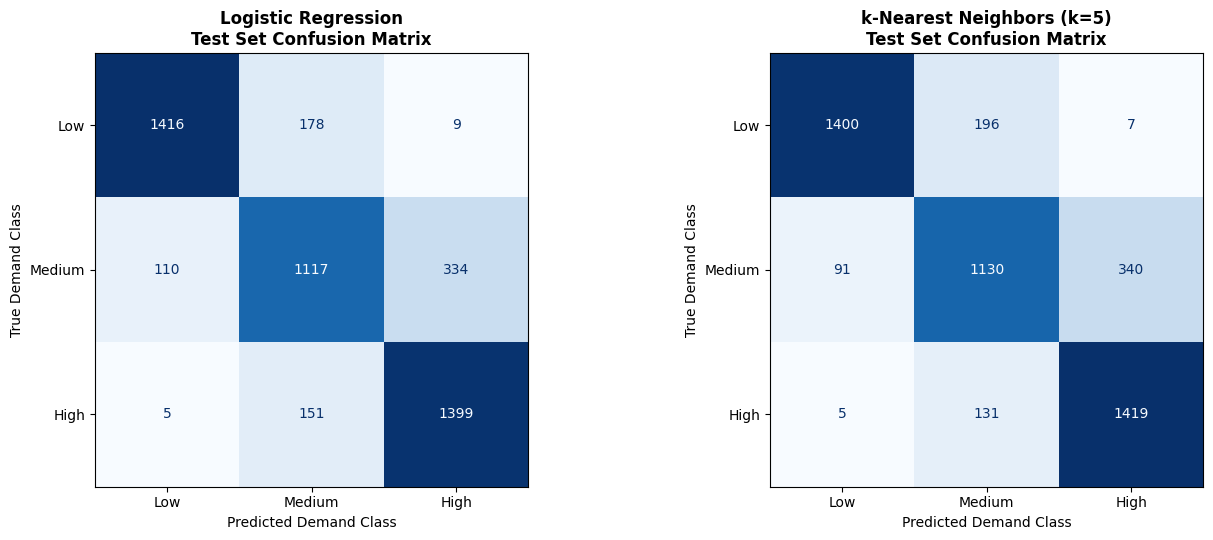

In [37]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize

models = [
    ("Logistic Regression", final_log_reg),
    ("k-Nearest Neighbors (k=5)", final_knn)
]

# -------------------------------------------------------------
# 1. SIDE-BY-SIDE CONFUSION MATRICES (TEST SET)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (name, model) in zip(axes, models):
    preds = model.predict(X_test_scaled)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        preds,
        display_labels=DEMAND_LABELS,
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"{name}\nTest Set Confusion Matrix", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Demand Class")
    ax.set_ylabel("True Demand Class")

plt.tight_layout()
plt.show()




Can see that our models do a good job at correctly predicting the station type (low, medium and high).

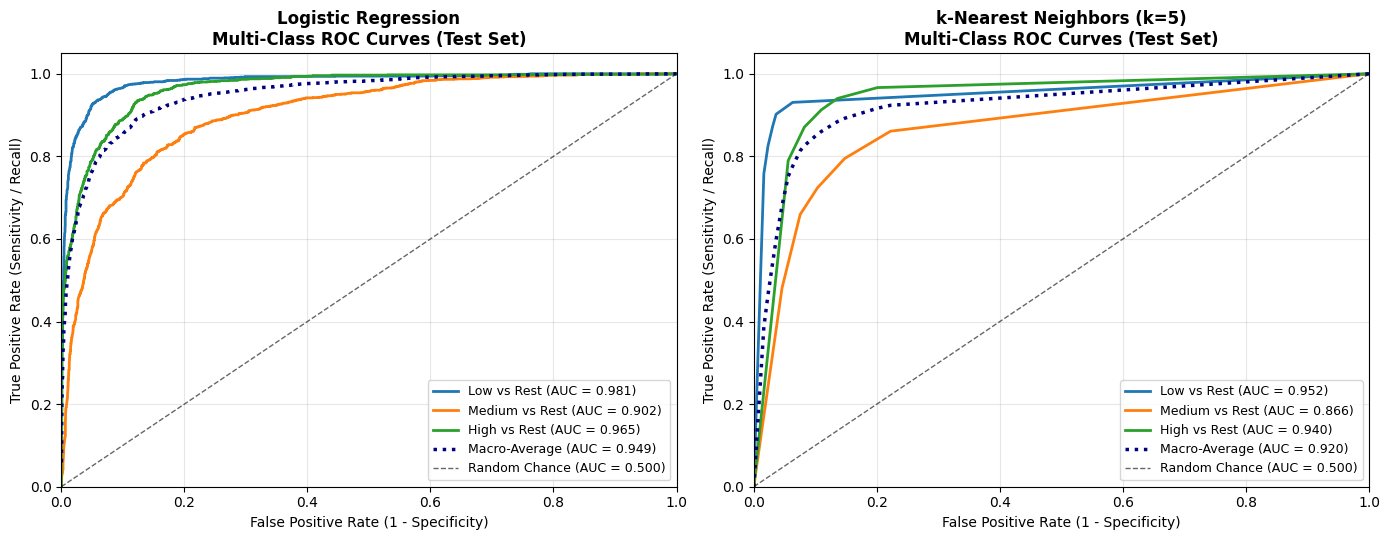

In [38]:
# -------------------------------------------------------------
# 2. MULTI-CLASS ROC CURVES (ONE-VS-REST ON TEST SET)
# -------------------------------------------------------------
# Binarize true labels into [0, 1, 2] columns for One-vs-Rest ROC curves
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = len(DEMAND_LABELS)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (name, model) in zip(axes, models):
    y_score = model.predict_proba(X_test_scaled)

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        ax.plot(
            fpr[i], tpr[i],
            color=colors[i],
            lw=2,
            label=f"{DEMAND_LABELS[i]} vs Rest (AUC = {roc_auc[i]:.3f})"
        )

    # Compute Macro-Average ROC curve & AUC
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    macro_auc = auc(all_fpr, mean_tpr)

    ax.plot(
        all_fpr, mean_tpr,
        color="navy", linestyle=":", linewidth=2.5,
        label=f"Macro-Average (AUC = {macro_auc:.3f})"
    )

    # Diagonal random-guess reference line
    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Random Chance (AUC = 0.500)")

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate (1 - Specificity)")
    ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
    ax.set_title(f"{name}\nMulti-Class ROC Curves (Test Set)", fontsize=12, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

From the plots, we can see that the logistic regression model is a smoother curve, and its values are higher than that for the kNN model. This is another reason we decided to move foreard with the logistic regression model, as a higher AUC for the ROC curve tells us it is better at classifying our stations.

## Part 5: Analytical Reflection (1 Page Required-Very important)

1. **Does the final model generalize well?**

For the regression tasks, the final model (Decision tree with depth 8) generalizes reasonably well. It is better than the baseline on the Test set for both departures (~ 3.0%) and arrivals (~ 3.2%), and in every test month, station group (by demand level), and rain condition. However, the Test set was used more than once, since the new features and additional checks were done after our initial submission, so the results may be a bit optimistic.
For the classification task, the results were acceptable. Test accuracy is ~ 0.83 for both logistic regression and kNN, which is a little lower than on the Validation set (~ 0.88).

2. **Structural weaknesses:**

The linear regression model predicts too high for Low demand stations. The decision tree's results show that the new feature `station_hour_dow_avg` dominates the feature importance, so the improvement it shows over the baseline comes mostly from the rainy hours.
All regression models still predicted too low on the busiest hours, which are the hours that matter most for growth planning. Stations that first appear after the training months have no historical data and get the average of the 3 nearest stations. This is better than the citywide average, but the predictions still end up too high and it assumes that stations that are close together always have similar demand. Also, our training data has only one full season (2023) plus May 2024, so the models see very little of the growth from year to year.

3. **Real-world deployment risks:**

For the classification task, we think that precision is more important than recall. It costs more to build a station or add docks where they are not needed than it would to miss a high-demand area. Another risk is that the bike share network keeps growing, so a model trained on past years will always meet new stations that it knows nothing about. We were not able to do the business check from 1.2 (comparing the stations classified as High in 2024 with the stations added in 2025).

4. **Was augmentation beneficial?**

We did not use data generation or augmentation. The zero-trip hours are actual observations, and the demand classes are close to equal in size.

5. **Future improvements for the regression models:**

- Improvements from version 1 that we applied in this update:

    - In this updated version for Milestone 4, we added new features that helped the regression models find the shape of the stations and make better predictions than our previous models.
    - We also reported the errors separately for low, medium, and high demand stations, as well as for different weather conditions (dry, light rain, heavy rain) and found that these showed the advantage of the models we built more than just using the average.
    - We tuned the decision tree. For the new decision tree with the added features, the validation error began going up after a depth of around 8-10, so we no longer tried depths beyond 20. We also found that minimum leaf sizes made very little difference compared to depth, so we used a minimum leaf size of 100 for both regression models.

- The following are improvements that we have not yet tried:
    - Add a feature that captures growth, since `year` had almost no effect in either model.
    - Look for additional datasets that may help add useful features to the models. As we found with using the coordinates (latitude and longitude) to recalculate the average departures and arrivals for new stations, considering nearby stations helped the regression models predict better. For future improvements, finding datasets showing the TTC network (nearby subway or bus stations) or other similar datasets related to transportation or infrastructure characteristics may surface some useful features we can use.